# Monitor Drift 

Visualizes the output of `run_monitor_drift_experiment`
(`thesis.experiments.monitor_drift`): for each shortlisted config, a
schema+model is mined/fit once on window 0's train split (same design as
`temporal_decay.py` -- W_src is always the first window) and frozen. For
symbolic configs, a deployment-scoped `DynamicSchema` (Vk) is built from
that same mining pass. The frozen schema/model/Vk are then walked forward
one window at a time from `h=0` (W_src's own held-out test split) to
`h=n_windows-1`, and at every horizon the drift monitor
(`thesis.monitor.monitor.run_monitor_window`) runs against the frozen Vk
over that horizon's raw incoming alert groups.

This is **observe-only**: the monitor's action (`NO_ACTION`/`SOFT_ALERT`/
`RETRAIN_ONLY`/`REMINE_AND_RETRAIN`) is recorded but nothing is ever
actually re-mined or retrained. `baseline` configs have no `DynamicSchema`
(nothing was mined), so the monitor never runs for them -- their rows carry
no monitor columns.

Loads four artifacts: `per_horizon_results.csv` (model decay metrics +
per-horizon monitor summary), `decay_summary.csv` (reused unmodified from
`temporal_decay.py`), `monitor_signals.csv` (dense long format -- every
predicate/rule signal at every horizon, elevated or not), and
`monitor_alarms.csv` (the `elevated == True` subset of `monitor_signals.csv`
-- the "when did the monitor fire, and why" log).

In [93]:
from __future__ import annotations

import pandas as pd
import matplotlib.pyplot as plt

from thesis.monitor.signals import (
    CALIBRATION_DRIFT_THRESHOLD,
    PSI_ELEVATED_THRESHOLD,
    PSI_SIGNIFICANT_THRESHOLD,
)
from thesis.paths import ARTIFACTS_DIR

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## Thresholds

Edit and re-run below -- nothing past this cell needs to change.

Action colors/markers follow a status palette (escalating severity), not an
arbitrary categorical one: `SOFT_ALERT` (warning) -> `RETRAIN_ONLY` (serious)
-> `REMINE_AND_RETRAIN` (critical). Each action is also encoded by marker
shape, not color alone.

In [94]:
SCENARIO = "cscas"
RUN_ID = "20260921_212704"  # pinned: latest run (RUN_ID=None) is 20260921_214627,
                             # a narrow symbolic/rf/gran=0.05-only run -- this is the
                             # last FULL-grid monitor_drift run (baseline/symbolic x
                             # rf/xgboost x 0.1/0.05, 8 configs), needed for a real
                             # Analysis 3 threshold sweep

PRIMARY_METRIC = "auc"  # which metric to draw as the main degradation curve
SOURCE_COLOR = "#CC3311"  # h=0 (W_src's own held-out test split)
LINE_COLOR = "#4477AA"

# Status palette (escalating severity), never reused for anything else.
ACTION_COLORS = {
    "SOFT_ALERT": "#fab219",       # warning
    "RETRAIN_ONLY": "#ec835a",     # serious
    "REMINE_AND_RETRAIN": "#d03b3b",  # critical
}
ACTION_MARKERS = {
    "SOFT_ALERT": "^",
    "RETRAIN_ONLY": "s",
    "REMINE_AND_RETRAIN": "X",
}

# Which config's alarm detail to print in section 4 -- see the printed
# config list in that section, then set this to its row index.
CONFIG_SELECT = 0

In [95]:
run_dir_base = ARTIFACTS_DIR / "experiments" / "monitor_drift" / SCENARIO
# Only consider run directories -- run_dir_base also holds
# _derived_shortlist.csv (written by --structural-configs runs), and
# sorting unfiltered would pick that file as "latest" since "_" sorts after
# digits, then crash trying to treat it as a directory.
run_dirs = [p for p in run_dir_base.iterdir() if p.is_dir()]
run_dir = run_dir_base / RUN_ID if RUN_ID else sorted(run_dirs)[-1]

per_horizon = pd.read_csv(run_dir / "per_horizon_results.csv")
decay_summary = pd.read_csv(run_dir / "decay_summary.csv")
monitor_signals = pd.read_csv(run_dir / "monitor_signals.csv")
monitor_alarms = pd.read_csv(run_dir / "monitor_alarms.csv")

print(f"Loaded from {run_dir}")
print(f"per_horizon: {len(per_horizon)} rows, monitor_signals: {len(monitor_signals)} rows, "
      f"monitor_alarms: {len(monitor_alarms)} rows")

Loaded from /Users/annavisman/stack/TUDelft/thesis/msc-thesis/artifacts/experiments/monitor_drift/cscas/20260921_212704
per_horizon: 128 rows, monitor_signals: 2048 rows, monitor_alarms: 86 rows


## 1. Degradation curves + monitor alarms

One detector, three views: F1 / FPR / AUC side by side vs. horizon (window
index), for a single fixed config (`symbolic`, gran=0.05, RF) rather than a
grid over every config -- the earlier one-metric-many-configs layout was
too busy to read. Monitor alarms are overlaid: a marker at every horizon
where the monitor's action was not `NO_ACTION`, shaped/colored by which
action fired. `h=0` (W_src's own held-out test split) is starred; every
other point is a fully external window.

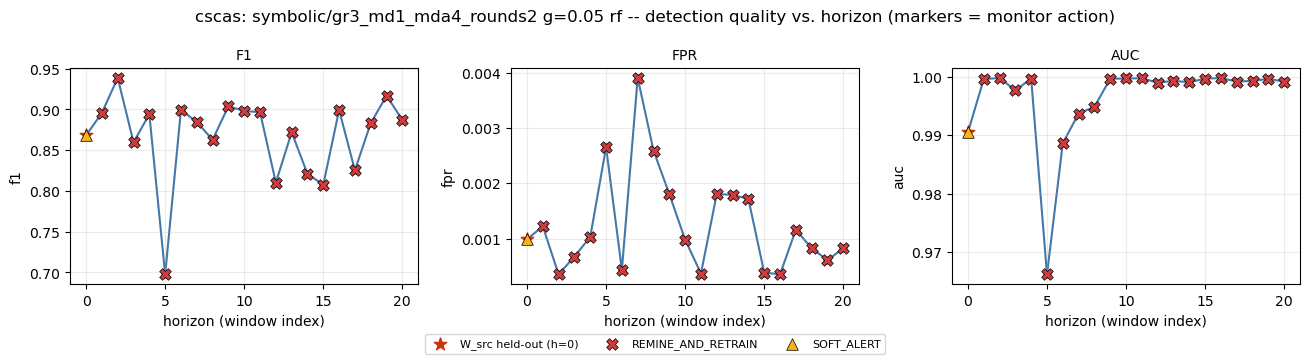

In [96]:
CONFIG_COLS = ["feature_set", "mining_setting", "granularity", "model"]


def config_label(row) -> str:
    return f"{row['feature_set']}/{row['mining_setting']} g={row['granularity']:g} {row['model']}"


def ordered_configs(df: pd.DataFrame) -> pd.DataFrame:
    # Ordered by granularity (not first-appearance) so configs at the same
    # granularity land next to each other for visibility.
    return (
        df[CONFIG_COLS].drop_duplicates()
        .sort_values(["granularity", "feature_set", "mining_setting"])
        .reset_index(drop=True)
    )


def plot_degradation_curves_with_alarms(gran: float, model: str, metrics: list[str],
                                        feature_set: str = "symbolic",
                                        mining_setting=None) -> None:
    """One panel per metric (not per config) -- gran/model/feature_set are
    fixed so the row reads as "one detector, three views", instead of the
    earlier one-metric-many-configs grid which was too busy to read."""
    mining_setting = mining_setting or (
        per_horizon.loc[per_horizon["feature_set"].eq("symbolic"), "mining_setting"]
        .dropna().iloc[0]
    )
    mask = (
        per_horizon["feature_set"].eq(feature_set)
        & per_horizon["mining_setting"].eq(mining_setting)
        & per_horizon["granularity"].eq(gran)
        & per_horizon["model"].eq(model)
    )
    sub_all = per_horizon[mask].sort_values("horizon_window_index")
    if sub_all.empty:
        print(f"no data for feature_set={feature_set}, model={model}, gran={gran:g}")
        return

    ncols = len(metrics)
    fig, axes = plt.subplots(1, ncols, figsize=(4.4 * ncols, 3.4), squeeze=False)

    for ax, metric in zip(axes[0], metrics):
        if metric not in sub_all.columns:
            ax.axis("off")
            continue
        source = sub_all[sub_all["is_source_window"]]
        rest = sub_all[~sub_all["is_source_window"]]

        ax.plot(sub_all["horizon_window_index"], sub_all[metric], "-", color=LINE_COLOR, zorder=1)
        ax.scatter(rest["horizon_window_index"], rest[metric], color=LINE_COLOR, zorder=3, s=25)
        if not source.empty:
            ax.scatter(
                source["horizon_window_index"], source[metric],
                color=SOURCE_COLOR, marker="*", s=90, zorder=5,
                label="W_src held-out (h=0)",
            )

        alarmed = sub_all[sub_all["action"].notna() & (sub_all["action"] != "NO_ACTION")]
        for action, group in alarmed.groupby("action"):
            ax.scatter(
                group["horizon_window_index"], group[metric],
                color=ACTION_COLORS.get(action, "#898781"),
                marker=ACTION_MARKERS.get(action, "x"),
                s=70, zorder=6, edgecolors="black", linewidths=0.5,
                label=action,
            )

        ax.set_title(metric.upper(), fontsize=10)
        ax.set_xlabel("horizon (window index)")
        ax.set_ylabel(metric)
        ax.grid(alpha=0.25)

    handles, labels = [], []
    for ax in axes[0]:
        h, l = ax.get_legend_handles_labels()
        for hh, ll in zip(h, l):
            if ll not in labels:
                handles.append(hh)
                labels.append(ll)
    if handles:
        fig.legend(
            handles, labels, loc="lower center", ncol=min(len(labels), 5),
            bbox_to_anchor=(0.5, -0.05), fontsize=8,
        )

    fig.suptitle(
        f"{SCENARIO}: {feature_set}/{mining_setting} g={gran:g} {model} -- "
        "detection quality vs. horizon (markers = monitor action)"
    )
    fig.tight_layout()


plot_degradation_curves_with_alarms(0.05, "rf", ["f1", "fpr", "auc"])

## 2. Decay summary

Score/FPR at `h=0` (W_src's own held-out test split) vs. the last horizon
actually reached (`h_max`), and their difference -- reused unmodified from
`temporal_decay.py::_build_decay_summary`. Purely about model performance;
doesn't reference the monitor at all.

In [97]:
sort_col = f"decay_rate_{PRIMARY_METRIC}"
decay_summary.sort_values(sort_col, ascending=False) if sort_col in decay_summary.columns else decay_summary

,feature_set,mining_setting,granularity,model,h_max,auc_at_h0,auc_at_h20,decay_rate_auc,f1_at_h0,f1_at_h20,decay_rate_f1,accuracy_at_h0,accuracy_at_h20,decay_rate_accuracy,precision_at_h0,precision_at_h20,decay_rate_precision,recall_at_h0,recall_at_h20,decay_rate_recall,fpr_at_h0,fpr_at_h20,fpr_drift,auc_at_h10,f1_at_h10,accuracy_at_h10,precision_at_h10,recall_at_h10,fpr_at_h10
5,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,20,0.999694,0.969181,0.030513,0.907383,0.691557,0.215826,0.998352,0.991449,0.006902,0.946779,0.707403,0.239376,0.871134,0.676404,0.194730,0.000458,0.004022,0.003564,NaN,NaN,NaN,NaN,NaN,NaN
7,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,10,0.999694,NaN,0.028787,0.907383,NaN,0.162179,0.998352,NaN,0.005120,0.946779,NaN,0.172806,0.871134,NaN,0.152637,0.000458,NaN,0.002473,0.970907,0.745204,0.993231,0.773973,0.718497,0.002931
1,baseline,NaN,0.05,xgboost,20,0.998347,0.994520,0.003827,0.853691,0.696104,0.157587,0.997396,0.992548,0.004848,0.890756,0.824615,0.066141,0.819588,0.602247,0.217340,0.000940,0.001841,0.000901,NaN,NaN,NaN,NaN,NaN,NaN
3,baseline,NaN,0.10,xgboost,10,0.998347,NaN,0.003467,0.853691,NaN,0.112705,0.997396,NaN,0.003631,0.890756,NaN,0.024554,0.819588,NaN,0.172189,0.000940,NaN,0.000456,0.994880,0.740986,0.993765,0.866203,0.647399,0.001397
4,symbolic,gr3_md1_mda4_rounds2,0.05,rf,20,0.990463,0.999130,-0.008667,0.868074,0.887049,-0.018975,0.997611,0.996959,0.000652,0.889189,0.936330,-0.047140,0.847938,0.842697,0.005242,0.000989,0.000824,-0.000165,NaN,NaN,NaN,NaN,NaN,NaN
6,symbolic,gr3_md1_mda4_rounds2,0.10,rf,10,0.990463,NaN,-0.008929,0.868074,NaN,-0.033496,0.997611,NaN,0.000207,0.889189,NaN,-0.054553,0.847938,NaN,-0.015068,0.000989,NaN,-0.000270,0.999392,0.901570,0.997404,0.943742,0.863006,0.000719
2,baseline,NaN,0.10,rf,10,0.983923,NaN,-0.009652,0.874317,NaN,0.243988,0.997802,NaN,0.007469,0.930233,NaN,0.264209,0.824742,NaN,0.226476,0.000579,NaN,0.003612,0.993575,0.630329,0.990333,0.666023,0.598266,0.004191
0,baseline,NaN,0.05,rf,20,0.983923,0.994827,-0.010905,0.874317,0.561488,0.312829,0.997802,0.988360,0.009442,0.930233,0.602317,0.327916,0.824742,0.525843,0.298900,0.000579,0.004991,0.004412,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Signal buildup below threshold

The maximum PSI across all single predicates (Signal 1) and the maximum
calibration drift across all compound rules (Signal 2), per horizon --
shows drift building up even *before* it crosses the elevated line. Both
signals are computed from the mined schema/predicates evaluated against
alert-group data, not from a downstream model's predictions, so they are
identical across models for the same (feature\_set, mining\_setting,
granularity) -- one representative config is shown, not one panel per
model. Reference lines are drawn at the actual threshold constants
imported from `thesis.monitor.signals`, so this plot can never drift out
of sync with the real monitor thresholds. `baseline` configs are absent
(no `DynamicSchema`, no signals).

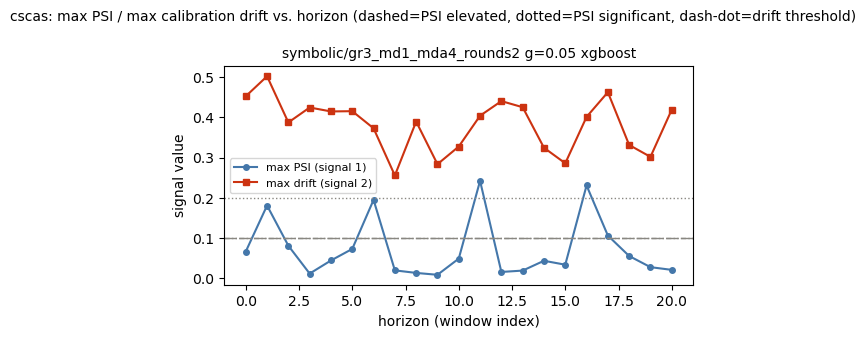

In [98]:
def plot_signal_buildup(gran: float = None) -> None:
    """Signal 1/2 are computed from the mined schema/predicates evaluated
    against alert-group data, not from a downstream model's predictions --
    identical across models for the same (feature_set, mining_setting,
    granularity), so a single representative config is shown, not one
    panel per model."""
    if monitor_signals.empty:
        print("No monitor signals recorded (no symbolic configs ran, or no horizons produced signals).")
        return

    configs = ordered_configs(monitor_signals)
    if gran is not None:
        configs = configs[configs["granularity"].eq(gran)].reset_index(drop=True)
    if configs.empty:
        print(f"No symbolic configs at gran={gran}.")
        return
    cfg_row = configs.iloc[0]

    fig, ax = plt.subplots(figsize=(5.5, 3.4))
    mask = (monitor_signals[CONFIG_COLS] == cfg_row).all(axis=1)
    sub = monitor_signals[mask]

    sig1 = (
        sub[sub["signal_type"] == "signal_1"]
        .groupby("horizon_window_index")["metric_value"].max()
    )
    sig2 = (
        sub[sub["signal_type"] == "signal_2"]
        .groupby("horizon_window_index")["metric_value"].max()
    )

    ax.plot(sig1.index, sig1.values, "-o", color=LINE_COLOR, ms=4, label="max PSI (signal 1)")
    ax.plot(sig2.index, sig2.values, "-s", color=SOURCE_COLOR, ms=4, label="max drift (signal 2)")
    ax.axhline(PSI_ELEVATED_THRESHOLD, color="#898781", linestyle="--", linewidth=1)
    ax.axhline(PSI_SIGNIFICANT_THRESHOLD, color="#898781", linestyle=":", linewidth=1)
    ax.axhline(CALIBRATION_DRIFT_THRESHOLD, color="#898781", linestyle="-.", linewidth=1)

    ax.set_title(config_label(cfg_row), fontsize=10)
    ax.set_xlabel("horizon (window index)")
    ax.set_ylabel("signal value")
    ax.legend(fontsize=8, loc="best")

    fig.suptitle(
        f"{SCENARIO}: max PSI / max calibration drift vs. horizon "
        "(dashed=PSI elevated, dotted=PSI significant, dash-dot=drift threshold)",
        fontsize=10,
    )
    fig.tight_layout()


plot_signal_buildup(gran=0.05)

## 4. Alarm inspection

The direct "which feature, which value, which class" readout:
`monitor_alarms.csv` (the `elevated == True` subset of `monitor_signals.csv`)
filtered to one selected config (`CONFIG_SELECT` above), sorted by horizon.
`signal_1` rows carry `field`/`operator`/`value`/`predicate_type`/`direction`;
`signal_2` rows carry `conditions`/`prediction` instead.

In [99]:
available_configs = (
    monitor_alarms[CONFIG_COLS].drop_duplicates().reset_index(drop=True)
    if not monitor_alarms.empty
    else pd.DataFrame(columns=CONFIG_COLS)
)
available_configs

,feature_set,mining_setting,granularity,model
0,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost
1,symbolic,gr3_md1_mda4_rounds2,0.10,rf
2,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost
3,symbolic,gr3_md1_mda4_rounds2,0.05,rf


In [100]:
if available_configs.empty:
    print("No alarms were raised in this run.")
else:
    cfg_row = available_configs.iloc[CONFIG_SELECT]
    mask = (monitor_alarms[CONFIG_COLS] == cfg_row).all(axis=1)
    cols = [
        "horizon_window_index", "signal_type", "identifier",
        "field", "operator", "value", "predicate_type", "direction",
        "conditions", "prediction",
        "mined_value", "observed_value", "metric_value", "elevated", "significant",
    ]
    display(monitor_alarms[mask].sort_values("horizon_window_index")[cols])

,horizon_window_index,signal_type,identifier,field,operator,value,predicate_type,direction,conditions,prediction,mined_value,observed_value,metric_value,elevated,significant
0,0,signal_2,rule:27086a5fb20c,NaN,NaN,NaN,NaN,NaN,"(('signature_id_similarity', '<=', 0.318775147...",attack,1.0,0.548023,0.451977,True,NaN
1,1,signal_2,rule:27086a5fb20c,NaN,NaN,NaN,NaN,NaN,"(('signature_id_similarity', '<=', 0.318775147...",attack,1.0,0.551508,0.448492,True,NaN
2,2,signal_2,rule:27086a5fb20c,NaN,NaN,NaN,NaN,NaN,"(('signature_id_similarity', '<=', 0.318775147...",attack,1.0,0.580738,0.419262,True,NaN
3,3,signal_2,rule:27086a5fb20c,NaN,NaN,NaN,NaN,NaN,"(('signature_id_similarity', '<=', 0.318775147...",attack,1.0,0.608244,0.391756,True,NaN
4,4,signal_2,rule:27086a5fb20c,NaN,NaN,NaN,NaN,NaN,"(('signature_id_similarity', '<=', 0.318775147...",attack,1.0,0.693257,0.306743,True,NaN
5,5,signal_2,rule:27086a5fb20c,NaN,NaN,NaN,NaN,NaN,"(('signature_id_similarity', '<=', 0.318775147...",attack,1.0,0.700069,0.299931,True,NaN
6,6,signal_2,rule:27086a5fb20c,NaN,NaN,NaN,NaN,NaN,"(('signature_id_similarity', '<=', 0.318775147...",attack,1.0,0.576680,0.423320,True,NaN
7,7,signal_2,rule:27086a5fb20c,NaN,NaN,NaN,NaN,NaN,"(('signature_id_similarity', '<=', 0.318775147...",attack,1.0,0.628031,0.371969,True,NaN
8,8,signal_2,rule:27086a5fb20c,NaN,NaN,NaN,NaN,NaN,"(('signature_id_similarity', '<=', 0.318775147...",attack,1.0,0.650652,0.349348,True,NaN
9,9,signal_2,rule:27086a5fb20c,NaN,NaN,NaN,NaN,NaN,"(('signature_id_similarity', '<=', 0.318775147...",attack,1.0,0.610827,0.389173,True,NaN


## 5. Calibration EDA -- setup

The sections below (5-8) exist to answer one question: **how should
`PSI_ELEVATED_THRESHOLD` / `PSI_SIGNIFICANT_THRESHOLD` /
`CALIBRATION_DRIFT_THRESHOLD` in `thesis.monitor.signals` be set**, before
the monitor is wired into a live system-eval loop that actually triggers
remine+retrain on `REMINE_AND_RETRAIN`. Everything here is a **post-hoc
re-aggregation** of `monitor_signals.csv` / `per_horizon_results.csv` --
no re-mining, no re-fitting. It needs a *current* run: `base_attack_rate`
(pi) and `attack_rate_h` (pi_h, per horizon) must already be columns in
the loaded CSVs -- re-run `run_monitor_drift_experiment` if they're
missing.


In [101]:
import json

import numpy as np

from thesis.monitor.signals import DEFAULT_MIN_SAMPLES_SIGNAL_2, compute_psi
from thesis.monitor.state import MonitorState
from thesis.monitor.triggers import DEFAULT_CONSECUTIVE_WINDOWS, classify_action

for _col in ("base_attack_rate",):
    assert _col in per_horizon.columns, (
        f"'{_col}' missing from per_horizon_results.csv -- this run predates "
        "the pi/pi_h logging addition; re-run run_monitor_drift_experiment."
    )
for _col in ("attack_rate_h",):
    assert _col in per_horizon.columns, (
        f"'{_col}' missing from per_horizon_results.csv -- re-run "
        "run_monitor_drift_experiment."
    )

# Only symbolic configs ever carry monitor signals (baseline has no
# DynamicSchema, so monitor_signals is empty for them by construction).
symbolic_configs = ordered_configs(monitor_signals) if not monitor_signals.empty else (
    ordered_configs(per_horizon).iloc[0:0]
)
print(f"{len(symbolic_configs)} config(s) with monitor signals")

4 config(s) with monitor signals


## 6. Analysis 1 -- signal-vs-decay overlay

For each symbolic config: `PRIMARY_METRIC(h)` (left axis, from
`per_horizon`) against $\overline{\mathrm{PSI}}(h)$ (mean PSI over all
single predicates, Signal 1) and $\overline{\Delta c}(h)$ (mean
calibration drift over compound rules with `n_matching >=
DEFAULT_MIN_SAMPLES_SIGNAL_2`, Signal 2), right axis. Does the signal rise
before, alongside, or unrelated to the metric's drop?

The cross-correlation table below quantifies lead/lag beyond eyeballing:
for each config and signal, correlate the signal series against the
*cumulative decay* `decay(h) = metric(0) - metric(h)` at lags
`-MAX_LAG..MAX_LAG` (positive lag = signal leads decay by that many
horizons) and reports the lag with the strongest correlation.

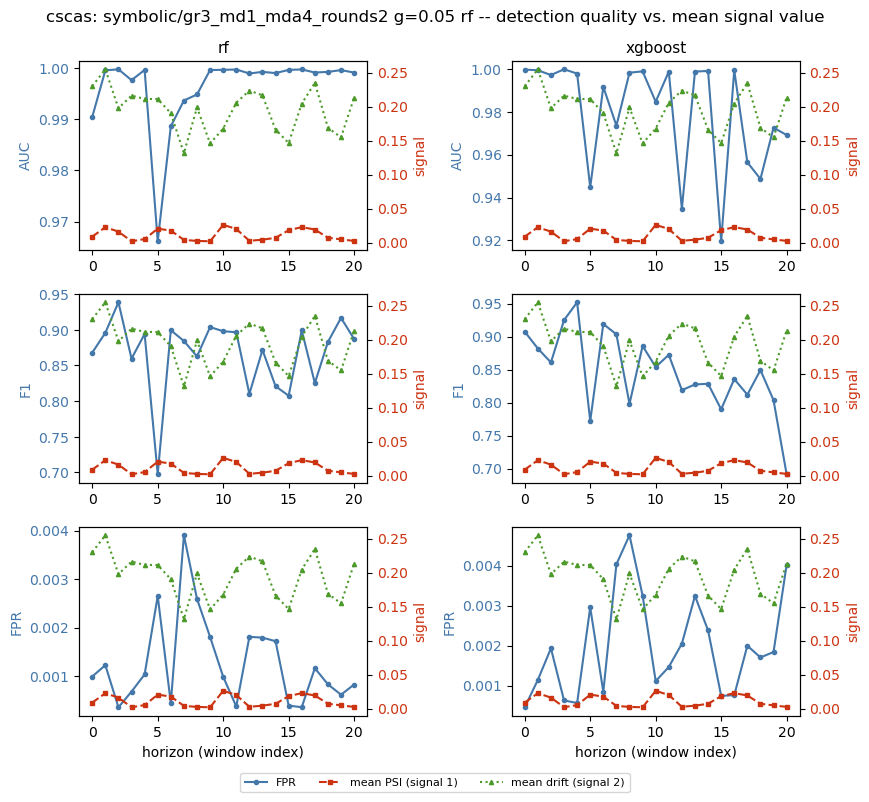

In [102]:
MAX_LAG = 3


def mean_signal_series(cfg_row, signal_type: str, min_n: int | None = None,
                        n_col: str | None = None) -> pd.Series:
    mask = (
        (monitor_signals[CONFIG_COLS] == cfg_row).all(axis=1)
        & (monitor_signals["signal_type"] == signal_type)
    )
    sub = monitor_signals[mask]
    if min_n is not None and n_col is not None:
        sub = sub[sub[n_col].fillna(0) >= min_n]
    return sub.groupby("horizon_window_index")["metric_value"].mean()


def decay_series(cfg_row, metric: str) -> pd.Series:
    mask = (per_horizon[CONFIG_COLS] == cfg_row).all(axis=1)
    sub = per_horizon[mask].sort_values("horizon_window_index")
    s = sub.set_index("horizon_window_index")[metric]
    return s.iloc[0] - s  # cumulative decay-so-far, positive = worse


def plot_signal_vs_decay(gran: float, metrics: list[str]) -> None:
    """Rows = metrics, columns = models -- one detector's quality curves
    (fixed gran, symbolic schema) against the same two mean-signal series
    in every row, since the signals don't depend on metric."""
    configs = symbolic_configs[symbolic_configs["granularity"].eq(gran)]
    configs = configs.sort_values("model").reset_index(drop=True)
    n_models = len(configs)
    if n_models == 0:
        print(f"No symbolic configs at gran={gran}.")
        return
    nrows = len(metrics)
    fig, axes = plt.subplots(
        nrows, n_models, figsize=(4.4 * n_models, 2.6 * nrows), squeeze=False,
    )
    for row, metric in enumerate(metrics):
        for col, (_, cfg_row) in enumerate(configs.iterrows()):
            ax = axes[row][col]
            mask = (per_horizon[CONFIG_COLS] == cfg_row).all(axis=1)
            sub = per_horizon[mask].sort_values("horizon_window_index")
            l1, = ax.plot(sub["horizon_window_index"], sub[metric], "-o", color=LINE_COLOR,
                          ms=3, label=metric.upper())
            ax.set_ylabel(metric.upper(), color=LINE_COLOR)
            ax.tick_params(axis="y", labelcolor=LINE_COLOR)

            ax2 = ax.twinx()
            psi_s = mean_signal_series(cfg_row, "signal_1")
            drift_s = mean_signal_series(
                cfg_row, "signal_2", min_n=DEFAULT_MIN_SAMPLES_SIGNAL_2, n_col="n_matching"
            )
            l2, = ax2.plot(psi_s.index, psi_s.values, "--s", color=SOURCE_COLOR, ms=3,
                           label="mean PSI (signal 1)")
            l3, = ax2.plot(drift_s.index, drift_s.values, ":^", color="#4c9a2a", ms=3,
                           label="mean drift (signal 2)")
            ax2.set_ylabel("signal", color=SOURCE_COLOR)
            ax2.tick_params(axis="y", labelcolor=SOURCE_COLOR)

            if row == 0:
                ax.set_title(f"{cfg_row['model']}", fontsize=11)
            if row == nrows - 1:
                ax.set_xlabel("horizon (window index)")

    handles = [l1, l2, l3]
    labels = [h.get_label() for h in handles]
    fig.legend(handles, labels, loc="lower center", ncol=3,
               bbox_to_anchor=(0.5, -0.03), fontsize=8)

    fig.suptitle(f"{SCENARIO}: {config_label(configs.iloc[0])} -- detection quality vs. mean signal value")
    fig.tight_layout()


plot_signal_vs_decay(gran=0.05, metrics=["auc", "f1", "fpr"])

In [103]:
def best_lag_corr(signal: pd.Series, decay: pd.Series, max_lag: int = MAX_LAG):
    """Pearson corr(signal(h), decay(h + lag)) for lag in [-max_lag, max_lag],
    over each pair's common horizon index. Returns (best_lag, best_corr) --
    NaN pair if fewer than 3 overlapping points at every lag."""
    best_lag, best_corr = None, -np.inf
    for lag in range(-max_lag, max_lag + 1):
        shifted_decay = decay.shift(-lag)
        joined = pd.concat([signal, shifted_decay], axis=1).dropna()
        if len(joined) < 3:
            continue
        corr = joined.iloc[:, 0].corr(joined.iloc[:, 1])
        if pd.notna(corr) and corr > best_corr:
            best_lag, best_corr = lag, corr
    return best_lag, (None if best_lag is None else best_corr)


xcorr_rows = []
for _, cfg_row in symbolic_configs.iterrows():
    decay_s = decay_series(cfg_row, PRIMARY_METRIC)
    for signal_type, label, kwargs in (
        ("signal_1", "PSI", {}),
        ("signal_2", "calibration_drift",
         dict(min_n=DEFAULT_MIN_SAMPLES_SIGNAL_2, n_col="n_matching")),
    ):
        sig_s = mean_signal_series(cfg_row, signal_type, **kwargs)
        lag, corr = best_lag_corr(sig_s, decay_s)
        xcorr_rows.append({**cfg_row.to_dict(), "signal": label,
                            "best_lag": lag, "corr_at_best_lag": corr})

xcorr_df = pd.DataFrame(xcorr_rows)
xcorr_df

,feature_set,mining_setting,granularity,model,signal,best_lag,corr_at_best_lag
0,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,PSI,2,0.154231
1,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,calibration_drift,2,0.000887
2,symbolic,gr3_md1_mda4_rounds2,0.05,rf,PSI,0,0.183782
3,symbolic,gr3_md1_mda4_rounds2,0.05,rf,calibration_drift,2,0.211444
4,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,PSI,0,0.326937
5,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,calibration_drift,-3,0.633760
6,symbolic,gr3_md1_mda4_rounds2,0.10,rf,PSI,2,0.370229
7,symbolic,gr3_md1_mda4_rounds2,0.10,rf,calibration_drift,-3,0.708918


## 7. Analysis 2 -- isolating the pi-confound

Signal 1's `mined_value` (`p_expected`) is already
`attack_support*pi + benign_support*(1-pi)` with the **frozen** `pi`
(`base_attack_rate` at mining time). If the incoming traffic's true attack
rate `pi_h` (`attack_rate_h`) drifts away from `pi` without any real
per-predicate behavior change, PSI still rises -- a confound, not genuine
predicate drift.

`PSI_decoupled(p, h)` recomputes the expectation with `pi_h` in place of
the frozen `pi`: `e_decoupled(p, h) = attack_support(p)*pi_h +
benign_support(p)*(1-pi_h)`, then `compute_psi(e_decoupled, p_observed)` --
the same PSI formula, different expectation. If the original mean PSI
tracks `pi_h` moving away from `pi` while the decoupled PSI stays flat over
the same horizons, that's evidence Signal 1 is mostly re-detecting
attack-rate drift, not predicate drift.

<>:46: SyntaxWarning: invalid escape sequence '\p'
<>:48: SyntaxWarning: invalid escape sequence '\p'
<>:54: SyntaxWarning: invalid escape sequence '\p'
<>:57: SyntaxWarning: invalid escape sequence '\p'
<>:46: SyntaxWarning: invalid escape sequence '\p'
<>:48: SyntaxWarning: invalid escape sequence '\p'
<>:54: SyntaxWarning: invalid escape sequence '\p'
<>:57: SyntaxWarning: invalid escape sequence '\p'
/var/folders/69/6nn2sm8d7qq0p98t_qgp1ckr0000gn/T/ipykernel_65244/3972024747.py:46: SyntaxWarning: invalid escape sequence '\p'
  label="mean PSI (frozen $\pi$)")
/var/folders/69/6nn2sm8d7qq0p98t_qgp1ckr0000gn/T/ipykernel_65244/3972024747.py:48: SyntaxWarning: invalid escape sequence '\p'
  label="mean PSI (decoupled, $\pi_h$)")
/var/folders/69/6nn2sm8d7qq0p98t_qgp1ckr0000gn/T/ipykernel_65244/3972024747.py:54: SyntaxWarning: invalid escape sequence '\p'
  label="$\pi_h$ (true attack rate)")
/var/folders/69/6nn2sm8d7qq0p98t_qgp1ckr0000gn/T/ipykernel_65244/3972024747.py:57: SyntaxWarning:

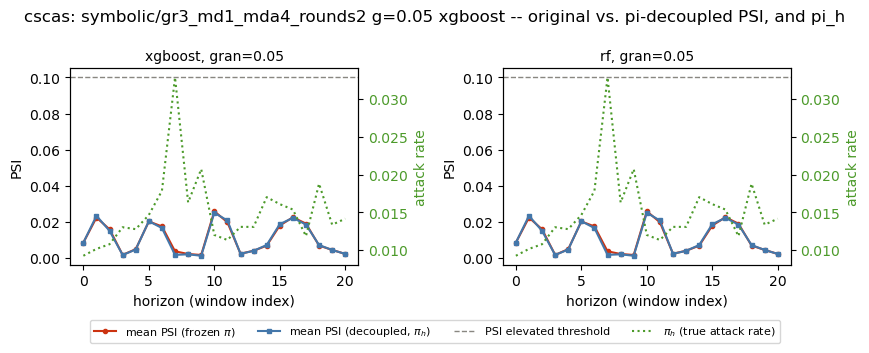

In [104]:
def decoupled_psi_series(cfg_row) -> pd.Series:
    mask = (
        (monitor_signals[CONFIG_COLS] == cfg_row).all(axis=1)
        & (monitor_signals["signal_type"] == "signal_1")
    )
    sig1 = monitor_signals[mask][
        ["horizon_window_index", "attack_support", "benign_support", "observed_value"]
    ].copy()

    pi_h = per_horizon[(per_horizon[CONFIG_COLS] == cfg_row).all(axis=1)].set_index(
        "horizon_window_index"
    )["attack_rate_h"]
    sig1["pi_h"] = sig1["horizon_window_index"].map(pi_h)
    sig1 = sig1.dropna(subset=["pi_h"])

    e_decoupled = (
        sig1["attack_support"] * sig1["pi_h"]
        + sig1["benign_support"] * (1 - sig1["pi_h"])
    )
    sig1["psi_decoupled"] = [
        compute_psi(e, o) for e, o in zip(e_decoupled, sig1["observed_value"])
    ]
    return sig1.groupby("horizon_window_index")["psi_decoupled"].mean()


def plot_pi_confound(gran: float = None) -> None:
    configs = symbolic_configs
    if gran is not None:
        configs = configs[configs["granularity"].eq(gran)].reset_index(drop=True)
    n = len(configs)
    if n == 0:
        print("No symbolic configs to plot.")
        return
    ncols = n
    fig, axes = plt.subplots(1, ncols, figsize=(4.4 * ncols, 3.2), squeeze=False)
    for i, cfg_row in configs.iterrows():
        ax = axes[0][i]
        psi_orig = mean_signal_series(cfg_row, "signal_1")
        psi_decoupled = decoupled_psi_series(cfg_row)
        pi_h = per_horizon[(per_horizon[CONFIG_COLS] == cfg_row).all(axis=1)].set_index(
            "horizon_window_index"
        )["attack_rate_h"]
        pi = cfg_row.get("base_attack_rate") if "base_attack_rate" in cfg_row else None

        l1, = ax.plot(psi_orig.index, psi_orig.values, "-o", color=SOURCE_COLOR, ms=3,
                       label="mean PSI (frozen $\pi$)")
        l2, = ax.plot(psi_decoupled.index, psi_decoupled.values, "-s", color=LINE_COLOR, ms=3,
                       label="mean PSI (decoupled, $\pi_h$)")
        thr = ax.axhline(PSI_ELEVATED_THRESHOLD, color="#898781", linestyle="--", linewidth=1,
                          label="PSI elevated threshold")

        ax2 = ax.twinx()
        l3, = ax2.plot(pi_h.index, pi_h.values, ":", color="#4c9a2a", linewidth=1.5,
                        label="$\pi_h$ (true attack rate)")
        if pi is not None:
            ax2.axhline(pi, color="#4c9a2a", linestyle="--", linewidth=1,
                        label="$\pi$ (frozen, mining-time)")
        ax2.set_ylabel("attack rate", color="#4c9a2a")
        ax2.tick_params(axis="y", labelcolor="#4c9a2a")

        ax.set_title(f"{cfg_row['model']}, gran={cfg_row['granularity']:g}", fontsize=10)
        ax.set_xlabel("horizon (window index)")
        ax.set_ylabel("PSI")

    # Collect legend entries from every axes in the figure (twin axes'
    # handles aren't visible from the primary axes' own legend call).
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc="lower center", ncol=min(len(labels), 5),
               bbox_to_anchor=(0.5, -0.08), fontsize=8)

    fig.suptitle(f"{SCENARIO}: {config_label(configs.iloc[0])} -- original vs. pi-decoupled PSI, and pi_h")
    fig.tight_layout()


plot_pi_confound(gran=0.05)

## 8. Analysis 3 -- threshold + trigger sensitivity

Sweeps every constant that decides *when the monitor would actually pull the
trigger* -- not just the PSI/calibration-drift cutoffs, but also how many
consecutive elevated windows it takes to escalate
(`DEFAULT_CONSECUTIVE_WINDOWS`), and how many labeled samples a rule needs
before Signal 2 counts it at all (`DEFAULT_MIN_SAMPLES_SIGNAL_2`). This
replays the real `MonitorState` / `classify_action` state machine
(`thesis.monitor`) over the already-logged raw signal values, so it stays a
re-aggregation, not a rerun -- **except** for `min_samples`: this run's own
floor (loaded from `config.json` below) is a hard lower bound on how far
that knob can be swept, since rows below it were never computed in the
first place. To sweep it lower, re-run the experiment once with
`--monitor-min-samples-signal-2 5` (or similar) -- the flag already exists,
no code change needed.

Per config: `h*` is the first horizon where `PRIMARY_DECAY_METRIC` drops
more than `DECAY_DROP_THRESHOLD` from its `h=0` value (stand-in for "real
decay has started"). At each `(psi_thr, cal_thr, min_samples,
consecutive_windows)` point, `detection_horizon` is the first horizon where
the *simulated* `classify_action` actually returns `trigger_remine = True`
-- the full escalation logic, including its same-window-both-signals-
elevated shortcut, not just "some signal exceeded its threshold".

**Definitions** (a judgment call -- revisit before writing this up):
- `lead_time = h* - detection_horizon`, only when both exist (positive =
  monitor triggers before the metric visibly drops).
- `false_alarm`: triggered at least once but `h*` never occurs.
- `missed`: `h*` occurs but the config never triggers before it.

The primary heatmaps below hold `min_samples`/`consecutive_windows` at this
run's actual floor / the current default (3); the two line plots afterward
sweep each of those two knobs on its own, holding the PSI/calibration
thresholds at `RECOMMENDED_PSI_THR`/`RECOMMENDED_CAL_THR` (edit these once
the heatmaps suggest better values, then re-run the line plots to sanity
check the other two knobs at that choice).

In [105]:
RUN_MIN_SAMPLES_SIGNAL_2 = int(
    json.loads((run_dir / "config.json").read_text())["monitor_min_samples_signal_2"]
)
print(
    f"This run's own Signal-2 floor: {RUN_MIN_SAMPLES_SIGNAL_2} "
    "(the lowest min_samples can be swept to below, without a rerun)"
)

PSI_THRESHOLD_GRID = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
CAL_THRESHOLD_GRID = [0.05, 0.10, 0.15, 0.20]
CONSECUTIVE_WINDOWS_GRID = sorted({1, 2, 3, 4, 5, DEFAULT_CONSECUTIVE_WINDOWS})
MIN_SAMPLES_GRID = sorted(
    m for m in {RUN_MIN_SAMPLES_SIGNAL_2, 10, 20, 30, 50} if m >= RUN_MIN_SAMPLES_SIGNAL_2
)
DECAY_DROP_THRESHOLD = 0.05
PRIMARY_DECAY_METRIC = "f1"

# Edit these once the heatmaps below suggest better values; the two line
# plots after the heatmaps sweep consecutive_windows/min_samples at
# whatever is set here.
RECOMMENDED_PSI_THR = PSI_ELEVATED_THRESHOLD
RECOMMENDED_CAL_THR = CALIBRATION_DRIFT_THRESHOLD


def decay_event_horizon(cfg_row, metric: str = PRIMARY_DECAY_METRIC,
                          drop: float = DECAY_DROP_THRESHOLD):
    mask = (per_horizon[CONFIG_COLS] == cfg_row).all(axis=1)
    sub = per_horizon[mask].sort_values("horizon_window_index")
    if sub.empty or metric not in sub.columns:
        return None
    h0 = sub[metric].iloc[0]
    hit = sub[(sub["horizon_window_index"] > 0) & (h0 - sub[metric] > drop)]
    return int(hit["horizon_window_index"].iloc[0]) if not hit.empty else None


def horizon_signal_series(cfg_row):
    """Per-horizon raw signal_1 PSI values and signal_2 (value, n_matching)
    pairs, kept ungrouped so a candidate min_samples floor can still be
    applied post-hoc."""
    mask = (monitor_signals[CONFIG_COLS] == cfg_row).all(axis=1)
    sub = monitor_signals[mask]
    sig1 = sub[sub["signal_type"] == "signal_1"][["horizon_window_index", "metric_value"]]
    sig2 = sub[sub["signal_type"] == "signal_2"][
        ["horizon_window_index", "metric_value", "n_matching"]
    ]
    return sig1, sig2


def horizon_elevated(sig1, sig2, psi_thr, cal_thr, min_samples) -> pd.DataFrame:
    max_psi = sig1.groupby("horizon_window_index")["metric_value"].max()
    sig2_ok = sig2[sig2["n_matching"] >= min_samples]
    max_drift = sig2_ok.groupby("horizon_window_index")["metric_value"].max()
    idx = sorted(set(max_psi.index) | set(max_drift.index))
    return pd.DataFrame(
        {
            "signal_1_elevated": [max_psi.get(h, 0) > psi_thr for h in idx],
            "signal_2_elevated": [max_drift.get(h, 0) > cal_thr for h in idx],
        },
        index=idx,
    )


def simulate_trigger_remine(elevated_df: pd.DataFrame, consecutive_windows: int):
    """Replays the real MonitorState/classify_action state machine over a
    horizon-ordered elevated-flag sequence; returns the first horizon where
    it would actually trigger_remine, or None if it never does."""
    state = MonitorState(scenario_name="calibration", deployed_schema_version=0)
    for h in elevated_df.index:
        s1 = bool(elevated_df.loc[h, "signal_1_elevated"])
        s2 = bool(elevated_df.loc[h, "signal_2_elevated"])
        state.advance(s1, s2)
        trigger, _ = classify_action(s1, s2, state, consecutive_windows=consecutive_windows)
        if trigger:
            return int(h)
    return None


sensitivity_rows = []
for _, cfg_row in symbolic_configs.iterrows():
    sig1, sig2 = horizon_signal_series(cfg_row)
    h_star = decay_event_horizon(cfg_row)
    for psi_thr in PSI_THRESHOLD_GRID:
        for cal_thr in CAL_THRESHOLD_GRID:
            for min_samples in MIN_SAMPLES_GRID:
                elevated_df = horizon_elevated(sig1, sig2, psi_thr, cal_thr, min_samples)
                for consecutive_windows in CONSECUTIVE_WINDOWS_GRID:
                    detection_h = simulate_trigger_remine(elevated_df, consecutive_windows)
                    lead_time = (
                        h_star - detection_h
                        if h_star is not None and detection_h is not None
                        else None
                    )
                    sensitivity_rows.append({
                        **cfg_row.to_dict(),
                        "psi_thr": psi_thr, "cal_thr": cal_thr,
                        "min_samples": min_samples,
                        "consecutive_windows": consecutive_windows,
                        "h_star": h_star, "detection_horizon": detection_h,
                        "lead_time": lead_time,
                        "false_alarm": h_star is None and detection_h is not None,
                        "missed": h_star is not None and detection_h is None,
                    })

sensitivity_df = pd.DataFrame(sensitivity_rows)
print(f"{len(sensitivity_df)} (config x threshold-combo) rows")

This run's own Signal-2 floor: 30 (the lowest min_samples can be swept to below, without a rerun)
960 (config x threshold-combo) rows


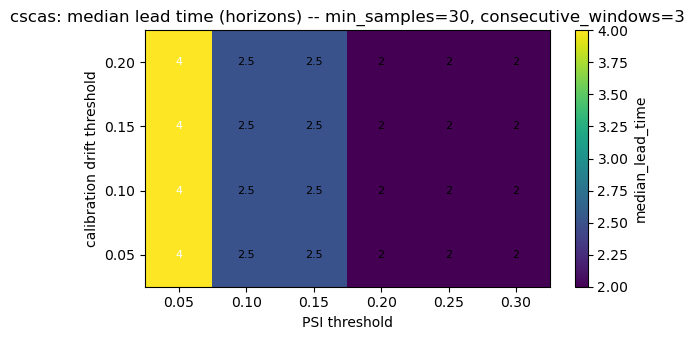

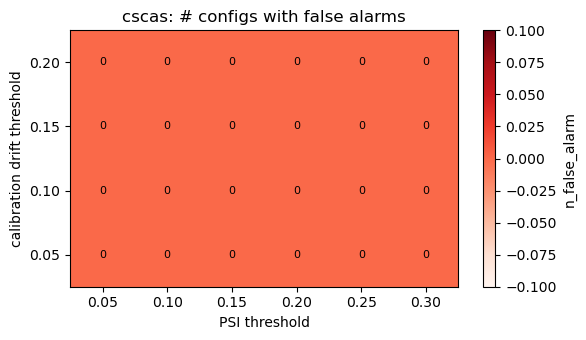

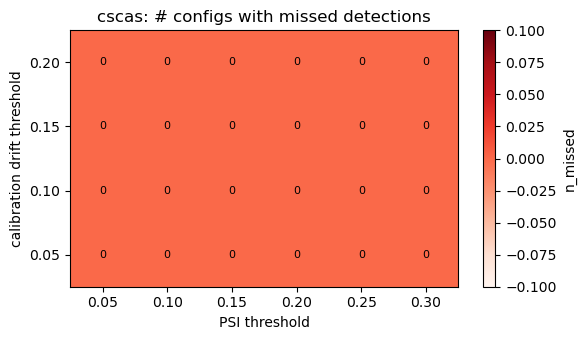

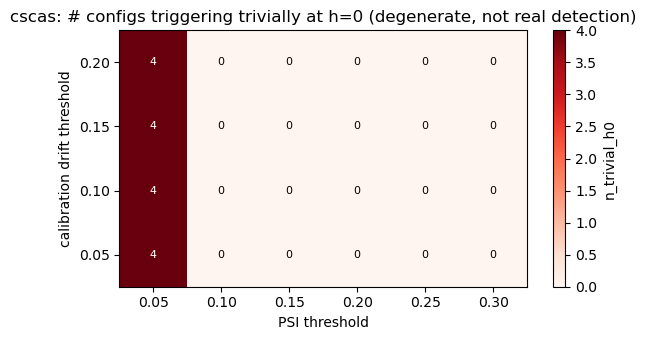

In [106]:
def sensitivity_heatmap(df: pd.DataFrame, value_col: str, title: str, cmap: str = "viridis") -> None:
    pivot = df.pivot(index="cal_thr", columns="psi_thr", values=value_col)
    fig, ax = plt.subplots(figsize=(6, 3.5))
    im = ax.imshow(pivot.values, cmap=cmap, aspect="auto", origin="lower")
    ax.set_xticks(range(len(pivot.columns)), [f"{v:.2f}" for v in pivot.columns])
    ax.set_yticks(range(len(pivot.index)), [f"{v:.2f}" for v in pivot.index])
    ax.set_xlabel("PSI threshold")
    ax.set_ylabel("calibration drift threshold")
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.values[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.2g}", ha="center", va="center", fontsize=8,
                         color="white" if im.norm(v) > 0.5 else "black")
    fig.colorbar(im, ax=ax, label=value_col)
    ax.set_title(title)
    fig.tight_layout()


primary_slice = sensitivity_df[
    (sensitivity_df["min_samples"] == RUN_MIN_SAMPLES_SIGNAL_2)
    & (sensitivity_df["consecutive_windows"] == DEFAULT_CONSECUTIVE_WINDOWS)
].copy()
# A config "trivially" triggers at horizon 0 -- before any real decay could
# possibly have been observed yet, since h=0 is W_src's own held-out split.
# n_false_alarm/n_missed/median_lead_time alone can't distinguish this from
# genuine early detection (both look like a valid positive lead time), so
# without this column the sweep table would make the lowest PSI threshold
# look strictly best -- it doesn't reveal that the signal is just always-on.
primary_slice["trivial_h0"] = primary_slice["detection_horizon"] == 0
primary_summary = primary_slice.groupby(["psi_thr", "cal_thr"]).agg(
    n_configs=("h_star", "size"),
    n_false_alarm=("false_alarm", "sum"),
    n_missed=("missed", "sum"),
    n_trivial_h0=("trivial_h0", "sum"),
    min_detection_horizon=("detection_horizon", "min"),
    median_lead_time=("lead_time", "median"),
).reset_index()

sensitivity_heatmap(
    primary_summary, "median_lead_time",
    f"{SCENARIO}: median lead time (horizons) -- "
    f"min_samples={RUN_MIN_SAMPLES_SIGNAL_2}, consecutive_windows={DEFAULT_CONSECUTIVE_WINDOWS}",
)
sensitivity_heatmap(primary_summary, "n_false_alarm", f"{SCENARIO}: # configs with false alarms", cmap="Reds")
sensitivity_heatmap(primary_summary, "n_missed", f"{SCENARIO}: # configs with missed detections", cmap="Reds")
sensitivity_heatmap(primary_summary, "n_trivial_h0",
                    f"{SCENARIO}: # configs triggering trivially at h=0 (degenerate, not real detection)",
                    cmap="Reds")

### Sweep table (LaTeX)

Same `primary_summary` data as the heatmaps above, as a table -- including
`n_trivial_h0` and `min_detection_horizon`, without which the table alone
would make the lowest PSI threshold look strictly best (highest median lead
time, zero false alarms/misses) without revealing that it's just an
always-on signal, not genuine early detection.

In [107]:
def sweep_table_to_latex(df: pd.DataFrame) -> str:
    lines = [
        r"\begin{table}[h]", r"\centering", r"\footnotesize",
        r"\begin{tabular}{rrrrrrr}", r"\toprule",
        r"\textbf{PSI thr} & \textbf{Cal.\ thr} & \# configs & \# false alarms & "
        r"\# missed & \# trivial $h{=}0$ & Median lead time \\",
        r"\midrule",
    ]
    for psi_thr, g in df.groupby("psi_thr"):
        g = g.reset_index(drop=True)
        for i, row in g.iterrows():
            psi_cell = f"{row['psi_thr']:.2f}" if i == 0 else ""
            lines.append(
                f"{psi_cell} & {row['cal_thr']:.2f} & {int(row['n_configs'])} & "
                f"{int(row['n_false_alarm'])} & {int(row['n_missed'])} & "
                f"{int(row['n_trivial_h0'])} & {row['median_lead_time']:.1f} \\\\"
            )
        lines.append(r"\midrule")
    lines[-1] = r"\bottomrule"
    lines.append(r"\end{tabular}")
    lines.append(
        r"\caption{Threshold sensitivity sweep (Analysis 3): simulated trigger timing "
        r"against the real \texttt{MonitorState}/\texttt{classify\_action} state machine, "
        rf"at \texttt{{consecutive\_windows}}={DEFAULT_CONSECUTIVE_WINDOWS} and "
        rf"\texttt{{min\_samples\_signal\_2}}={RUN_MIN_SAMPLES_SIGNAL_2} (this run's own floor), "
        r"across all 4 symbolic configs. \# trivial $h{=}0$ = configs whose simulated trigger "
        r"fires at horizon 0 -- before any real decay could have been observed yet -- a "
        r"degenerate always-on signal rather than genuine early detection; "
        r"\# false alarms/\# missed alone cannot distinguish this case, since it still reads "
        r"as a valid positive lead time. PSI=0.10 is the smallest threshold in the grid with "
        r"zero trivial triggers, which is why it is chosen over PSI=0.05 despite the latter's "
        r"higher raw median lead time. Calibration-drift threshold has no effect on any "
        r"outcome at any PSI threshold in this data.}"
    )
    lines.append(r"\label{tab:threshold-sensitivity-sweep}")
    lines.append(r"\end{table}")
    return "\n".join(lines)


print(sweep_table_to_latex(primary_summary))

\begin{table}[h]
\centering
\footnotesize
\begin{tabular}{rrrrrrr}
\toprule
\textbf{PSI thr} & \textbf{Cal.\ thr} & \# configs & \# false alarms & \# missed & \# trivial $h{=}0$ & Median lead time \\
\midrule
0.05 & 0.05 & 4 & 0 & 0 & 4 & 4.0 \\
 & 0.10 & 4 & 0 & 0 & 4 & 4.0 \\
 & 0.15 & 4 & 0 & 0 & 4 & 4.0 \\
 & 0.20 & 4 & 0 & 0 & 4 & 4.0 \\
\midrule
0.10 & 0.05 & 4 & 0 & 0 & 0 & 2.5 \\
 & 0.10 & 4 & 0 & 0 & 0 & 2.5 \\
 & 0.15 & 4 & 0 & 0 & 0 & 2.5 \\
 & 0.20 & 4 & 0 & 0 & 0 & 2.5 \\
\midrule
0.15 & 0.05 & 4 & 0 & 0 & 0 & 2.5 \\
 & 0.10 & 4 & 0 & 0 & 0 & 2.5 \\
 & 0.15 & 4 & 0 & 0 & 0 & 2.5 \\
 & 0.20 & 4 & 0 & 0 & 0 & 2.5 \\
\midrule
0.20 & 0.05 & 4 & 0 & 0 & 0 & 2.0 \\
 & 0.10 & 4 & 0 & 0 & 0 & 2.0 \\
 & 0.15 & 4 & 0 & 0 & 0 & 2.0 \\
 & 0.20 & 4 & 0 & 0 & 0 & 2.0 \\
\midrule
0.25 & 0.05 & 4 & 0 & 0 & 0 & 2.0 \\
 & 0.10 & 4 & 0 & 0 & 0 & 2.0 \\
 & 0.15 & 4 & 0 & 0 & 0 & 2.0 \\
 & 0.20 & 4 & 0 & 0 & 0 & 2.0 \\
\midrule
0.30 & 0.05 & 4 & 0 & 0 & 0 & 2.0 \\
 & 0.10 & 4 & 0 & 0 & 0 & 2.0

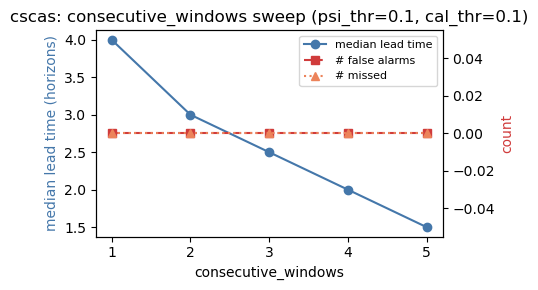

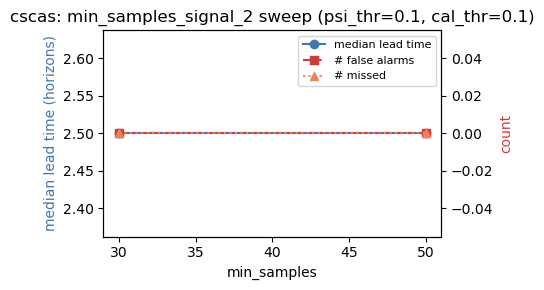

In [108]:
def plot_1d_sweep(param: str, grid: list, fixed: dict, title: str) -> None:
    mask = pd.Series(True, index=sensitivity_df.index)
    for k, v in fixed.items():
        mask &= sensitivity_df[k] == v
    sub = sensitivity_df[mask]
    agg = sub.groupby(param).agg(
        median_lead_time=("lead_time", "median"),
        n_false_alarm=("false_alarm", "sum"),
        n_missed=("missed", "sum"),
    ).reindex(grid)

    fig, ax1 = plt.subplots(figsize=(5, 3))
    ax1.plot(agg.index, agg["median_lead_time"], "-o", color=LINE_COLOR, label="median lead time")
    ax1.set_ylabel("median lead time (horizons)", color=LINE_COLOR)
    ax1.set_xlabel(param)
    ax2 = ax1.twinx()
    ax2.plot(agg.index, agg["n_false_alarm"], "--s", color="#d03b3b", label="# false alarms")
    ax2.plot(agg.index, agg["n_missed"], ":^", color="#ec835a", label="# missed")
    ax2.set_ylabel("count", color="#d03b3b")
    lines = ax1.get_lines() + ax2.get_lines()
    ax1.legend(lines, [l.get_label() for l in lines], fontsize=8, loc="best")
    ax1.set_title(title)
    fig.tight_layout()


plot_1d_sweep(
    "consecutive_windows", CONSECUTIVE_WINDOWS_GRID,
    fixed={"psi_thr": RECOMMENDED_PSI_THR, "cal_thr": RECOMMENDED_CAL_THR,
           "min_samples": RUN_MIN_SAMPLES_SIGNAL_2},
    title=f"{SCENARIO}: consecutive_windows sweep "
          f"(psi_thr={RECOMMENDED_PSI_THR}, cal_thr={RECOMMENDED_CAL_THR})",
)
plot_1d_sweep(
    "min_samples", MIN_SAMPLES_GRID,
    fixed={"psi_thr": RECOMMENDED_PSI_THR, "cal_thr": RECOMMENDED_CAL_THR,
           "consecutive_windows": DEFAULT_CONSECUTIVE_WINDOWS},
    title=f"{SCENARIO}: min_samples_signal_2 sweep "
          f"(psi_thr={RECOMMENDED_PSI_THR}, cal_thr={RECOMMENDED_CAL_THR})",
)

## 9. Label-starvation check (reporting only)

Signal 2 needs `n_matching >= DEFAULT_MIN_SAMPLES_SIGNAL_2` (30) labeled
groups per rule per horizon or it's skipped (`observed_value`/`metric_value`
`NaN`, `elevated=False` by construction -- see `compute_signal_2`). A
horizon is "starved" here if a majority of its compound rules were skipped.
`n_incoming_groups` vs. `n_labeled_groups` (already in `per_horizon_results`)
shows the same thing from the label-availability side directly.

In [109]:
def starvation_by_horizon(cfg_row) -> pd.DataFrame:
    mask = (
        (monitor_signals[CONFIG_COLS] == cfg_row).all(axis=1)
        & (monitor_signals["signal_type"] == "signal_2")
    )
    sub = monitor_signals[mask]
    frac_skipped = sub.groupby("horizon_window_index")["n_matching"].apply(
        lambda s: (s < DEFAULT_MIN_SAMPLES_SIGNAL_2).mean()
    )
    return frac_skipped.rename("frac_rules_skipped").to_frame()


starvation_rows = []
for _, cfg_row in symbolic_configs.iterrows():
    starv = starvation_by_horizon(cfg_row)
    pi_h = per_horizon[(per_horizon[CONFIG_COLS] == cfg_row).all(axis=1)].set_index(
        "horizon_window_index"
    )["attack_rate_h"]
    starv["attack_rate_h"] = starv.index.map(pi_h)
    starv["majority_skipped"] = starv["frac_rules_skipped"] > 0.5
    for h, row in starv.iterrows():
        starvation_rows.append({**cfg_row.to_dict(), "horizon_window_index": h, **row.to_dict()})

starvation_df = pd.DataFrame(starvation_rows)
if starvation_df.empty:
    print("No signal_2 rows to check.")
else:
    frac_starved = starvation_df["majority_skipped"].mean()
    print(f"{frac_starved:.1%} of (config, horizon) pairs had a majority of "
          "Signal 2 rules skipped for insufficient samples.")
    print()
    print("attack_rate_h when starved vs. not starved:")
    print(starvation_df.groupby("majority_skipped")["attack_rate_h"].describe()[
        ["count", "mean", "min", "max"]
    ])
    display(starvation_df.sort_values(["majority_skipped", "horizon_window_index"], ascending=[False, True]))

0.0% of (config, horizon) pairs had a majority of Signal 2 rules skipped for insufficient samples.

attack_rate_h when starved vs. not starved:
                  count      mean       min       max
majority_skipped                                     
False              64.0  0.014903  0.009269  0.032872


,feature_set,mining_setting,granularity,model,horizon_window_index,frac_rules_skipped,attack_rate_h,majority_skipped
0,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,0,0.0,0.009269,False
21,symbolic,gr3_md1_mda4_rounds2,0.05,rf,0,0.0,0.009269,False
42,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,0,0.0,0.009269,False
53,symbolic,gr3_md1_mda4_rounds2,0.10,rf,0,0.0,0.009269,False
1,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,1,0.0,0.010177,False
...,...,...,...,...,...,...,...,...
39,symbolic,gr3_md1_mda4_rounds2,0.05,rf,18,0.0,0.018809,False
19,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,19,0.0,0.013378,False
40,symbolic,gr3_md1_mda4_rounds2,0.05,rf,19,0.0,0.013378,False
20,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,20,0.0,0.014172,False


## 10. Monitor Attached -- setup

Loads the reactive counterpart to this run: `run_monitor_attached_experiment`
(`thesis.system_eval.monitor_attached`). Unlike everything above, that
experiment actually *acts* on the monitor's decision -- a sustained Signal 1
streak retrains the current model in place, a sustained Signal 2 streak
remines a new schema+Vk and retrains against it. `per_horizon` (loaded in
section 0 above) stays the **never-retrain** anchor here (the exact same
frozen-schema design as `temporal_decay.py`); `rolling_walk_forward`'s
`per_step_results.csv`, loaded below if present, is the **always-retrain**
anchor. All three share the same horizon axis when run with the same
`source_split_mode`/shortlist.

`events.csv` is one row per horizon where `trigger_remine` was `True`,
`executed` records whether the update actually happened (it can be skipped
if that horizon had no two-class labeled rows to train on), and every
executed row carries its own retrain/remine timing and schema churn.
`latency_sample.csv` holds individually-timed single-alert-group
encode+predict calls (not the batched per-horizon timing) for a genuine
p50/p95/p99 latency distribution.

In [110]:
ATTACHED_RUN_ID = None  # None -> latest run dir for SCENARIO -- both
                        # monitor_attached runs found (20260921_222814,
                        # 20260922_033604) are the same full 4-config grid, so
                        # latest-by-name is safe here
WALK_FORWARD_RUN_ID = "20260921_142835"  # pinned: latest (None) is 20260921_214259,
                             # a partial symbolic/rf-only run -- this is the last
                             # FULL-grid rolling_walk_forward run, same one
                             # 02_rolling_walk_forward.ipynb is pinned to

attached_run_dir_base = ARTIFACTS_DIR / "experiments" / "monitor_attached" / SCENARIO
attached_run_dirs = (
    [p for p in attached_run_dir_base.iterdir() if p.is_dir()]
    if attached_run_dir_base.exists()
    else []
)

if not attached_run_dirs:
    print(
        f"No monitor_attached runs found under {attached_run_dir_base} -- "
        "run scripts/system_eval/run_monitor_attached.py first. Sections 10-16 "
        "below will be skipped."
    )
    per_horizon_attached = pd.DataFrame()
    events_attached = pd.DataFrame()
    latency_attached = pd.DataFrame()
    attached_run_dir = None
else:
    attached_run_dir = (
        attached_run_dir_base / ATTACHED_RUN_ID if ATTACHED_RUN_ID else sorted(attached_run_dirs)[-1]
    )
    per_horizon_attached = pd.read_csv(attached_run_dir / "per_horizon_results.csv")
    events_attached = pd.read_csv(attached_run_dir / "events.csv")
    latency_attached = pd.read_csv(attached_run_dir / "latency_sample.csv")
    print(f"Loaded from {attached_run_dir}")
    print(
        f"per_horizon_attached: {len(per_horizon_attached)} rows, "
        f"events_attached: {len(events_attached)} rows "
        f"({int(events_attached['executed'].sum()) if 'executed' in events_attached.columns else 0} executed), "
        f"latency_attached: {len(latency_attached)} rows"
    )

# Always-retrain anchor (Experiment 3) -- optional, only used for the
# performance overlay in section 11.
walk_forward_run_dir_base = ARTIFACTS_DIR / "experiments" / "rolling_walk_forward" / SCENARIO
walk_forward_dirs = (
    [p for p in walk_forward_run_dir_base.iterdir() if p.is_dir()]
    if walk_forward_run_dir_base.exists()
    else []
)
if walk_forward_dirs:
    walk_forward_run_dir = (
        walk_forward_run_dir_base / WALK_FORWARD_RUN_ID
        if WALK_FORWARD_RUN_ID
        else sorted(walk_forward_dirs)[-1]
    )
    per_step_walk_forward = pd.read_csv(walk_forward_run_dir / "per_step_results.csv")
    print(f"Loaded always-retrain anchor from {walk_forward_run_dir} ({len(per_step_walk_forward)} rows)")
else:
    print(f"No rolling_walk_forward runs found under {walk_forward_run_dir_base} -- always-retrain overlay skipped.")
    per_step_walk_forward = pd.DataFrame()

Loaded from /Users/annavisman/stack/TUDelft/thesis/msc-thesis/artifacts/experiments/monitor_attached/cscas/20260922_033604
per_horizon_attached: 64 rows, events_attached: 34 rows (34 executed), latency_attached: 774 rows
Loaded always-retrain anchor from /Users/annavisman/stack/TUDelft/thesis/msc-thesis/artifacts/experiments/rolling_walk_forward/cscas/20260921_142835 (240 rows)


## 11. Monitor Attached vs. the two baselines

Where does the monitor-driven curve land between never-retrain (`per_horizon`,
flat) and always-retrain (`per_step_walk_forward`, retrains every step)? One
panel per shortlisted config: `PRIMARY_METRIC` for all three, with the
monitor-attached curve's executed retrain/remine events marked the same way
section 1's alarm markers were (status palette + shape).

Configs are matched across the three runs by `CONFIG_COLS`
(`feature_set`/`mining_setting`/`granularity`/`model`) -- a config only
plotted here if it exists in `per_horizon_attached`; the never-retrain and
always-retrain curves are overlaid wherever a matching config is found in
the respective run (missing quietly skipped, not an error, since these are
three separately-launched experiments).

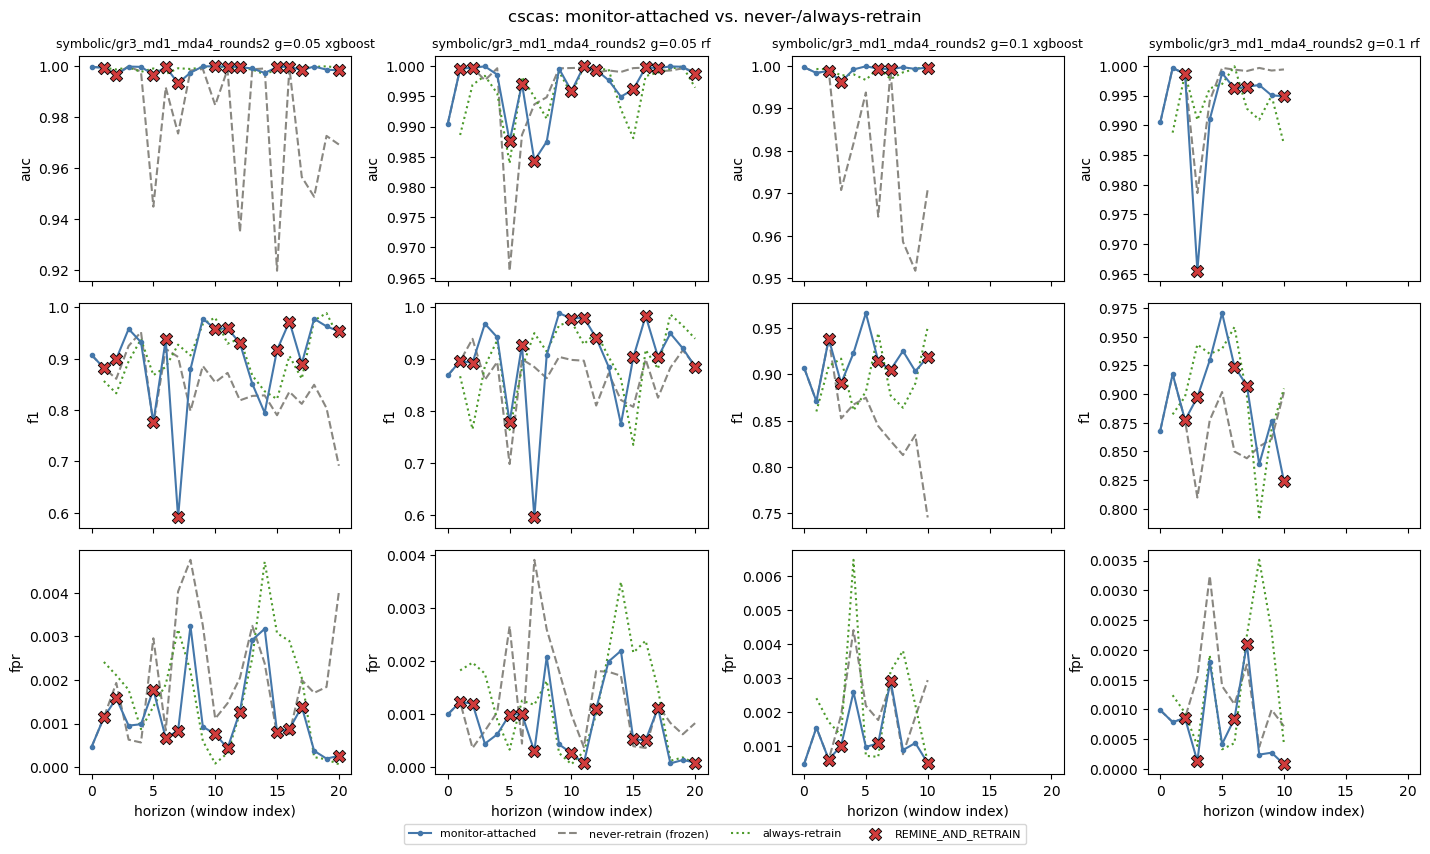

In [111]:
def plot_monitor_attached_vs_baselines(metrics: list[str] = None, model: str = None,
                                       gran: float = None, model_order: list[str] = None) -> None:
    """Rows = metrics, columns = configs -- same three-curve overlay
    (monitor-attached / never-retrain / always-retrain) repeated per
    metric, instead of one call per metric. `model`/`gran` restrict the
    columns (both set -> a single config, one column of panels).
    `model_order` fixes the left-to-right column order by model."""
    metrics = metrics or [PRIMARY_METRIC]
    if per_horizon_attached.empty:
        print("No monitor_attached run loaded -- nothing to plot.")
        return

    configs = ordered_configs(per_horizon_attached)
    if model is not None:
        configs = configs[configs["model"].eq(model)]
    if gran is not None:
        configs = configs[configs["granularity"].eq(gran)]
    if model_order is not None:
        configs = configs[configs["model"].isin(model_order)]
        configs = configs.sort_values("model", key=lambda s: s.map(model_order.index))
    configs = configs.reset_index(drop=True)
    if configs.empty:
        print(f"No monitor_attached config for model={model}, gran={gran}.")
        return
    ncols = len(configs)
    nrows = len(metrics)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(3.6 * ncols, 2.8 * nrows), squeeze=False, sharex=True,
    )

    for row, metric in enumerate(metrics):
        for col, (_, cfg_row) in enumerate(configs.iterrows()):
            ax = axes[row][col]

            mask_a = (per_horizon_attached[CONFIG_COLS] == cfg_row).all(axis=1)
            sub_a = per_horizon_attached[mask_a].sort_values("horizon_window_index")
            ax.plot(
                sub_a["horizon_window_index"], sub_a[metric], "-o", color=LINE_COLOR,
                ms=3, zorder=3, label="monitor-attached",
            )

            mask_f = (per_horizon[CONFIG_COLS] == cfg_row).all(axis=1)
            sub_f = per_horizon[mask_f].sort_values("horizon_window_index")
            if not sub_f.empty:
                ax.plot(
                    sub_f["horizon_window_index"], sub_f[metric], "--", color="#898781",
                    zorder=1, label="never-retrain (frozen)",
                )

            if not per_step_walk_forward.empty:
                mask_w = (per_step_walk_forward[CONFIG_COLS] == cfg_row).all(axis=1)
                sub_w = per_step_walk_forward[mask_w].sort_values("step_i")
                if not sub_w.empty and metric in sub_w.columns:
                    # step_i evaluates window (step_i + 1) -- shift onto the
                    # same horizon_window_index axis the other two curves use.
                    ax.plot(
                        sub_w["step_i"] + 1, sub_w[metric], ":", color="#4c9a2a",
                        zorder=2, label="always-retrain",
                    )

            events_mask = (
                (events_attached[CONFIG_COLS] == cfg_row).all(axis=1)
                if not events_attached.empty else None
            )
            if events_mask is not None:
                executed = events_attached[events_mask & events_attached["executed"]]
                for action, group in executed.groupby("action"):
                    y_vals = sub_a.set_index("horizon_window_index")[metric].reindex(
                        group["horizon_window_index"]
                    )
                    ax.scatter(
                        group["horizon_window_index"], y_vals,
                        color=ACTION_COLORS.get(action, "#898781"),
                        marker=ACTION_MARKERS.get(action, "x"),
                        s=80, zorder=6, edgecolors="black", linewidths=0.6, label=action,
                    )

            if row == 0 and ncols > 1:
                ax.set_title(config_label(cfg_row), fontsize=9)
            if row == nrows - 1:
                ax.set_xlabel("horizon (window index)")
            ax.set_ylabel(metric)

    handles, labels = [], []
    for ax_row in axes:
        for ax in ax_row:
            h, l = ax.get_legend_handles_labels()
            for hh, ll in zip(h, l):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if ncols > 1:
        if handles:
            fig.legend(handles, labels, loc="lower center", ncol=min(len(labels), 6),
                        bbox_to_anchor=(0.5, -0.02), fontsize=8)
        fig.suptitle(f"{SCENARIO}: monitor-attached vs. never-/always-retrain")
        fig.tight_layout()
    else:
        fig.suptitle(f"{SCENARIO}: monitor-attached vs. never-/always-retrain\n"
                     f"{config_label(configs.iloc[0])}", fontsize=10)
        fig.tight_layout()
        # after tight_layout, hanging below the figure, so the legend can't
        # cover the bottom panel's x-label in a single narrow column
        if handles:
            fig.legend(handles, labels, loc="upper center", ncol=2,
                        bbox_to_anchor=(0.5, 0.0), fontsize=8)


plot_monitor_attached_vs_baselines(["auc", "f1", "fpr"])

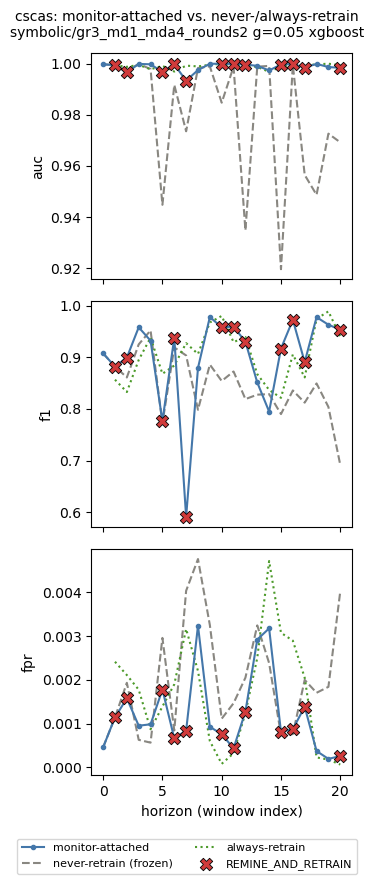

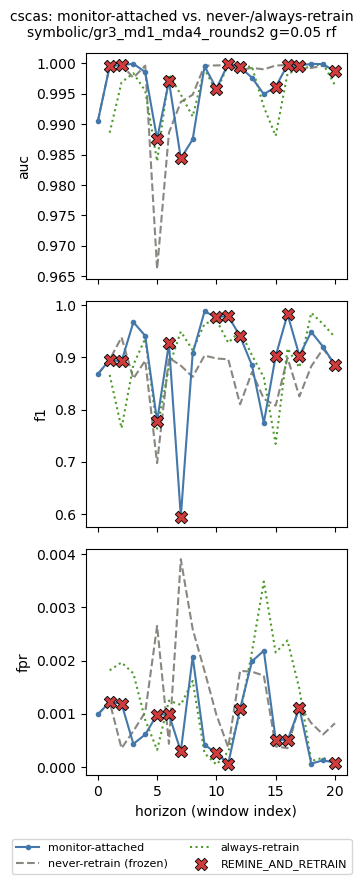

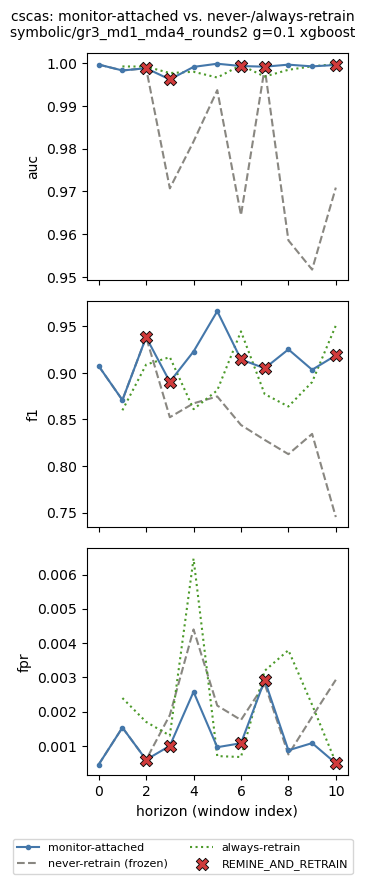

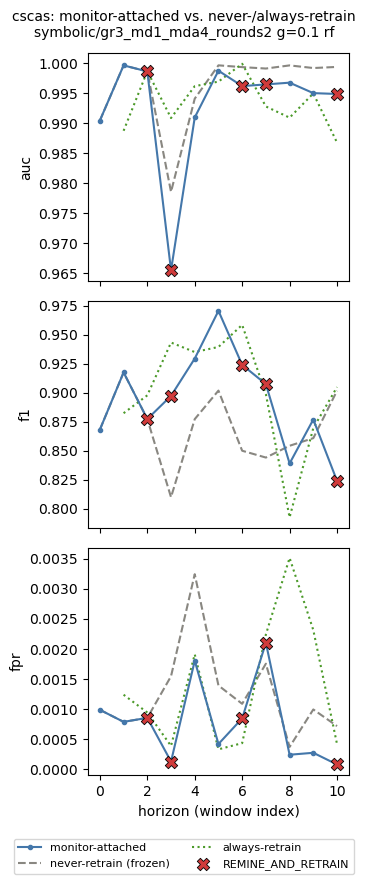

In [112]:
# One figure per (model, gran): the same three metric panels as above,
# stacked in a single column.
if not per_horizon_attached.empty:
    for _, _cfg in ordered_configs(per_horizon_attached).iterrows():
        plot_monitor_attached_vs_baselines(["auc", "f1", "fpr"],
                                           model=_cfg["model"], gran=_cfg["granularity"])

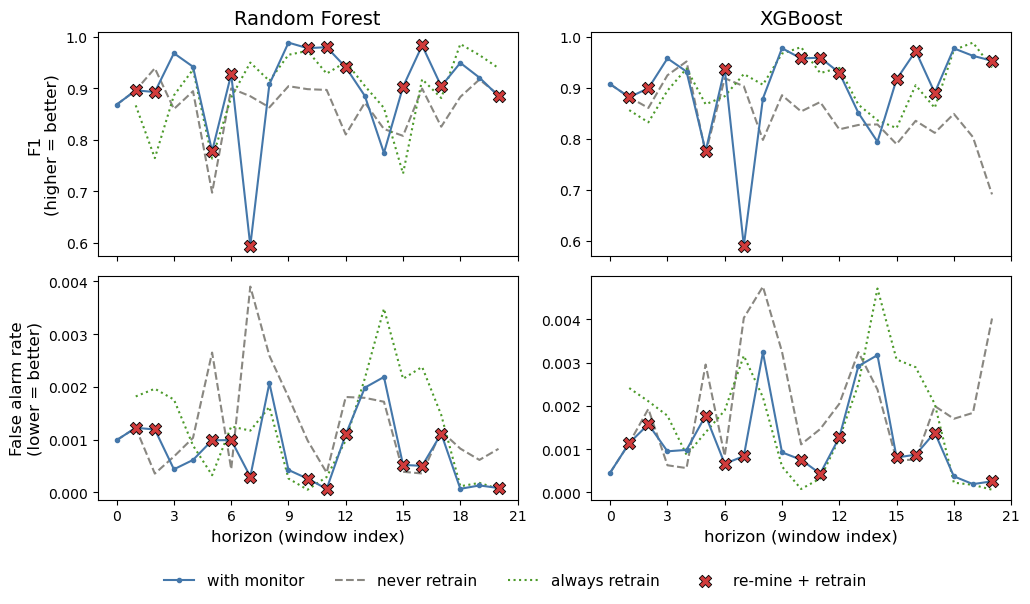

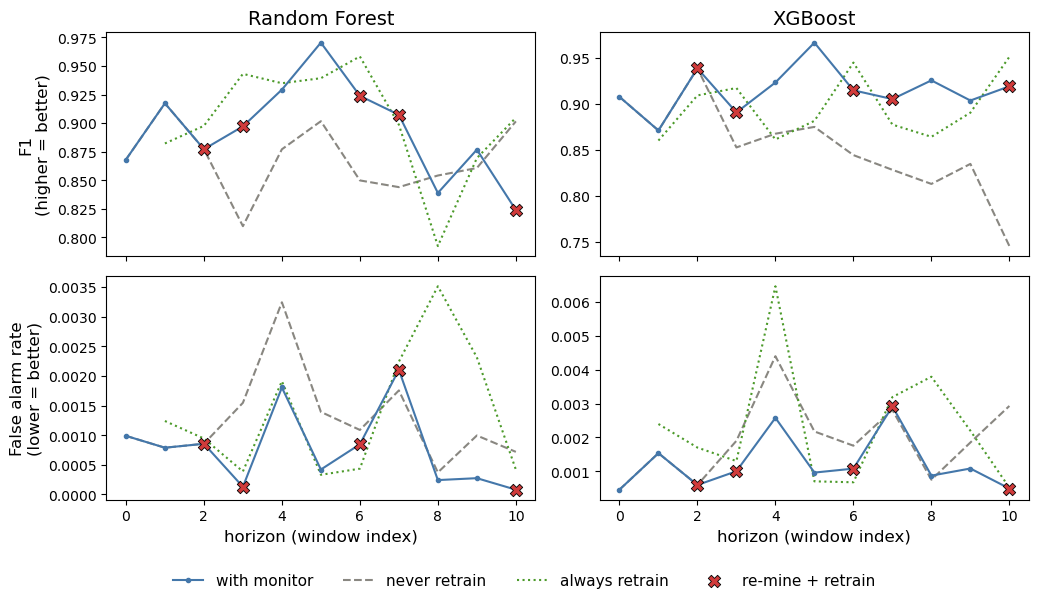

In [113]:
# Slide version: one figure per granularity, RF and XGBoost side by side,
# F1 over false-alarm rate, plain-language titles / row labels / legend.
from matplotlib.ticker import MaxNLocator

MODEL_DISPLAY = {"rf": "Random Forest", "xgboost": "XGBoost"}
ROW_DISPLAY = {"f1": "F1\n(higher = better)", "fpr": "False alarm rate\n(lower = better)"}
LEGEND_DISPLAY = {
    "monitor-attached": "with monitor",
    "never-retrain (frozen)": "never retrain",
    "always-retrain": "always retrain",
    "REMINE_AND_RETRAIN": "re-mine + retrain",
}


def plot_attached_slide(gran: float, metrics=("f1", "fpr"), models=("rf", "xgboost"),
                        fs: int = 12) -> None:
    plot_monitor_attached_vs_baselines(list(metrics), gran=gran, model_order=list(models))
    fig = plt.gcf()
    axes = [ax for ax in fig.axes]
    ncols = len(models)
    grid = [axes[r * ncols:(r + 1) * ncols] for r in range(len(metrics))]

    for ax in fig.legends:
        ax.remove()
    fig.suptitle("")
    for col, model in enumerate(models):
        grid[0][col].set_title(MODEL_DISPLAY.get(model, model), fontsize=fs + 2)
    for row, metric in enumerate(metrics):
        for col, ax in enumerate(grid[row]):
            ax.set_ylabel(ROW_DISPLAY.get(metric, metric) if col == 0 else "", fontsize=fs)
            ax.tick_params(labelsize=fs - 2)
    for ax in grid[-1]:
        ax.set_xlabel("horizon (window index)", fontsize=fs)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    handles, labels = [], []
    for ax in axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            l = LEGEND_DISPLAY.get(l, l)
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.set_size_inches(4.6 * ncols + 1.2, 2.9 * len(metrics))
    fig.tight_layout()
    fig.legend(handles, labels, loc="upper center", ncol=len(labels),
               bbox_to_anchor=(0.5, 0.0), fontsize=fs - 1, frameon=False)


if not per_horizon_attached.empty:
    for _gran in sorted(per_horizon_attached["granularity"].unique()):
        plot_attached_slide(_gran)

## 12. Retrain lag

For each config, `h*` is the same ground-truth decay horizon `decay_event_horizon`
computes in Analysis 3 above (`PRIMARY_DECAY_METRIC` drops more than
`DECAY_DROP_THRESHOLD` below its `h=0` value) -- deliberately recomputed
from `per_horizon` (the **frozen**, never-retrain curve), not from
`per_horizon_attached`'s own curve, since a monitor-driven curve's shape
changes once it starts retraining and would no longer mark "when decay
actually started" cleanly.

`retrain_lag = event_horizon - h*` for every *executed* event: negative
means the monitor acted before the frozen curve's own decay point would
have been visible, positive means it lagged behind it.

In [114]:
if events_attached.empty:
    print("No monitor_attached events loaded.")
else:
    lag_rows = []
    for _, cfg_row in ordered_configs(events_attached).iterrows():
        h_star = decay_event_horizon(cfg_row)
        mask = (events_attached[CONFIG_COLS] == cfg_row).all(axis=1) & events_attached["executed"]
        for _, ev in events_attached[mask].iterrows():
            lag_rows.append({
                **cfg_row.to_dict(),
                "horizon_window_index": ev["horizon_window_index"],
                "action": ev["action"],
                "h_star": h_star,
                "retrain_lag": (
                    ev["horizon_window_index"] - h_star if h_star is not None else None
                ),
            })

    retrain_lag_df = pd.DataFrame(lag_rows)
    if retrain_lag_df.empty:
        print("No executed retrain/remine events in this run.")
    else:
        display(retrain_lag_df)
        valid = retrain_lag_df.dropna(subset=["retrain_lag"])
        if not valid.empty:
            print(
                f"retrain_lag: mean={valid['retrain_lag'].mean():.2f}, "
                f"median={valid['retrain_lag'].median():.2f}, "
                f"n={len(valid)} (of {len(retrain_lag_df)} executed events; "
                f"{len(retrain_lag_df) - len(valid)} had no h* -- frozen curve never decayed by "
                f"{DECAY_DROP_THRESHOLD} on {PRIMARY_DECAY_METRIC})"
            )

,feature_set,mining_setting,granularity,model,horizon_window_index,action,h_star,retrain_lag
0,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,1,REMINE_AND_RETRAIN,5,-4
1,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,2,REMINE_AND_RETRAIN,5,-3
2,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,5,REMINE_AND_RETRAIN,5,0
3,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,6,REMINE_AND_RETRAIN,5,1
4,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,7,REMINE_AND_RETRAIN,5,2
5,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,10,REMINE_AND_RETRAIN,5,5
6,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,11,REMINE_AND_RETRAIN,5,6
7,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,12,REMINE_AND_RETRAIN,5,7
8,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,15,REMINE_AND_RETRAIN,5,10
9,symbolic,gr3_md1_mda4_rounds2,0.05,xgboost,16,REMINE_AND_RETRAIN,5,11


retrain_lag: mean=4.41, median=4.00, n=34 (of 34 executed events; 0 had no h* -- frozen curve never decayed by 0.05 on f1)


## 13. System Operationality 1 -- fast route vs. slow route cost

The fast route (Encoder + Model; grouping/preprocessing already happened
upstream of this experiment, since CSCAS alerts are pregrouped) is timed
once per horizon as a single batched encode+predict call over every
incoming group (`fast_route_wall_s`/`fast_route_cpu_s` in
`per_horizon_attached`) -- flat cost punctuated by the slow route's
occasional, expensive adaptation events (`t_mining_s`/`t_retrain_s`/
`t_deploy_s` + schema churn in `events_attached`, only on executed
horizons). There is no per-alert fast/slow *routing* split to report here
-- every alert always takes the fast route; the slow route just
occasionally replaces what the fast route is currently using.

`latency_attached` (individually-timed single-alert-group calls, not the
batched per-horizon number) gives the actual per-instance latency
distribution -- mean/p50/p95/p99 -- since a batched call only gives a mean.

Fast-route wall time (batched, per horizon) across all configs/horizons:
count    64.000000
mean     27.862447
std      14.710794
min       6.286438
50%      23.490603
95%      57.288065
99%      60.280773
max      60.332723
Name: fast_route_wall_s, dtype: float64

Single-alert-group latency (individually timed, latency_sample.csv):
  mean=0.424032s  p50=0.089534s  p95=1.716297s  p99=2.755537s  n=774


,feature_set,mining_setting,granularity,model,horizon_window_index,action,fast_route_before,fast_route_after,delta
0,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,2,REMINE_AND_RETRAIN,35.727604,34.696316,-1.031288
1,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,3,REMINE_AND_RETRAIN,34.696316,29.804639,-4.891677
2,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,6,REMINE_AND_RETRAIN,57.533119,34.915637,-22.617483
3,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,7,REMINE_AND_RETRAIN,34.915637,60.250263,25.334626
4,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,10,REMINE_AND_RETRAIN,51.314252,NaN,NaN
5,symbolic,gr3_md1_mda4_rounds2,0.10,rf,2,REMINE_AND_RETRAIN,21.856332,39.424390,17.568057
6,symbolic,gr3_md1_mda4_rounds2,0.10,rf,3,REMINE_AND_RETRAIN,39.424390,59.819077,20.394687
7,symbolic,gr3_md1_mda4_rounds2,0.10,rf,6,REMINE_AND_RETRAIN,60.332723,38.887835,-21.444888
8,symbolic,gr3_md1_mda4_rounds2,0.10,rf,7,REMINE_AND_RETRAIN,38.887835,48.428375,9.540541
9,symbolic,gr3_md1_mda4_rounds2,0.10,rf,10,REMINE_AND_RETRAIN,35.352319,NaN,NaN


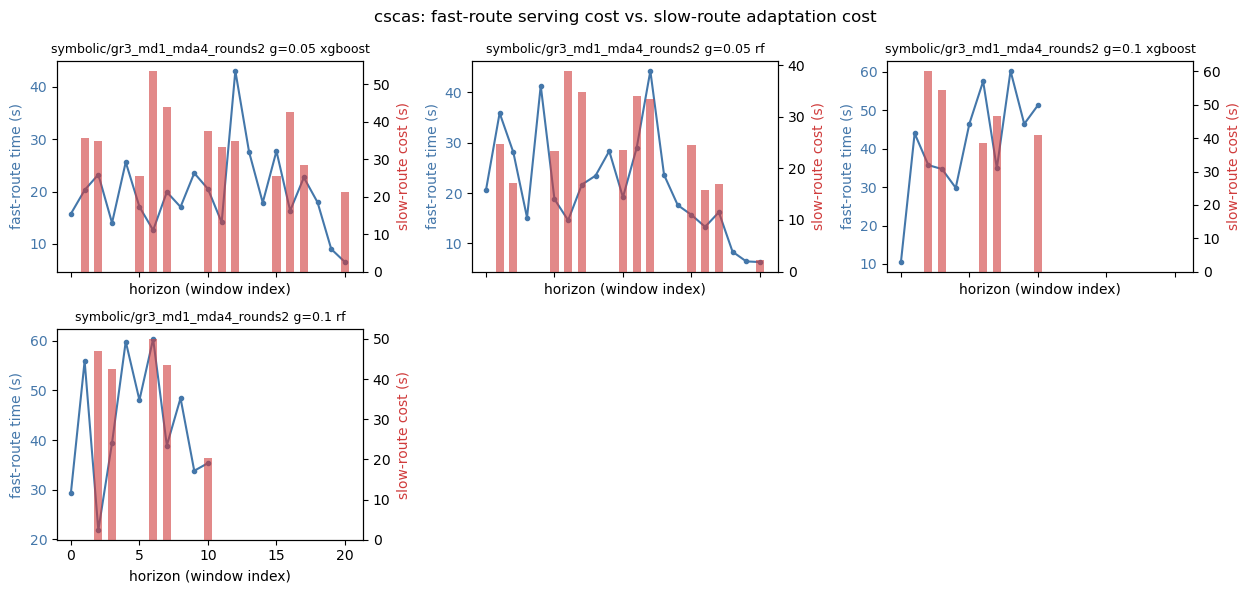

In [115]:
def plot_fast_vs_slow_route_cost() -> None:
    if per_horizon_attached.empty:
        print("No monitor_attached run loaded.")
        return

    configs = ordered_configs(per_horizon_attached)
    n = len(configs)
    ncols = 3
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(4.2 * ncols, 3.0 * nrows), squeeze=False, sharex=True,
    )

    for i, cfg_row in configs.iterrows():
        ax = axes[i // ncols][i % ncols]
        mask = (per_horizon_attached[CONFIG_COLS] == cfg_row).all(axis=1)
        sub = per_horizon_attached[mask].sort_values("horizon_window_index")

        ax.plot(sub["horizon_window_index"], sub["fast_route_wall_s"], "-o",
                 color=LINE_COLOR, ms=3, label="fast-route wall time")
        ax.set_ylabel("fast-route time (s)", color=LINE_COLOR)
        ax.tick_params(axis="y", labelcolor=LINE_COLOR)

        ev_mask = (events_attached[CONFIG_COLS] == cfg_row).all(axis=1) if not events_attached.empty else None
        if ev_mask is not None:
            executed = events_attached[ev_mask & events_attached["executed"]]
            if not executed.empty:
                ax2 = ax.twinx()
                slow_cost = (
                    executed[["t_mining_s", "t_retrain_s", "t_deploy_s"]].fillna(0).sum(axis=1)
                )
                colors = [ACTION_COLORS.get(a, "#898781") for a in executed["action"]]
                ax2.bar(executed["horizon_window_index"], slow_cost, width=0.6,
                         color=colors, alpha=0.6, label="slow-route cost (mine+retrain+deploy)")
                ax2.set_ylabel("slow-route cost (s)", color="#d03b3b")

        ax.set_title(config_label(cfg_row), fontsize=9)
        ax.set_xlabel("horizon (window index)")

    for j in range(n, nrows * ncols):
        axes[j // ncols][j % ncols].axis("off")
    fig.suptitle(f"{SCENARIO}: fast-route serving cost vs. slow-route adaptation cost")
    fig.tight_layout()


plot_fast_vs_slow_route_cost()

if not per_horizon_attached.empty:
    fr = per_horizon_attached["fast_route_wall_s"].dropna()
    print("Fast-route wall time (batched, per horizon) across all configs/horizons:")
    print(fr.describe(percentiles=[0.5, 0.95, 0.99]))

if not latency_attached.empty:
    lat = latency_attached["latency_s"]
    print("\nSingle-alert-group latency (individually timed, latency_sample.csv):")
    print(f"  mean={lat.mean():.6f}s  p50={lat.quantile(0.5):.6f}s  "
          f"p95={lat.quantile(0.95):.6f}s  p99={lat.quantile(0.99):.6f}s  n={len(lat)}")

if not events_attached.empty:
    executed = events_attached[events_attached["executed"]]
    if not executed.empty:
        # Before/after fast-route cost delta at each executed trigger --
        # "before" = this trigger horizon's own cost (pre-update), "after"
        # = the next horizon's cost under the newly deployed schema/model.
        delta_rows = []
        for _, ev in executed.iterrows():
            cfg_mask = (per_horizon_attached[CONFIG_COLS] == ev[CONFIG_COLS]).all(axis=1)
            sub = per_horizon_attached[cfg_mask].set_index("horizon_window_index")
            h = ev["horizon_window_index"]
            before = sub["fast_route_wall_s"].get(h)
            after = sub["fast_route_wall_s"].get(h + 1)
            delta_rows.append({
                **ev[CONFIG_COLS].to_dict(), "horizon_window_index": h, "action": ev["action"],
                "fast_route_before": before, "fast_route_after": after,
                "delta": (after - before) if pd.notna(before) and pd.notna(after) else None,
            })
        display(pd.DataFrame(delta_rows))

## 14. System Operationality 2 -- throughput and alert reduction

`In(t)` = `n_alerts_in`, `Out(t)` = `n_alerts_escalated` (no ungroupable
bucket -- CSCAS is pregrouped, so every group is scored, never a separate
manual-inspection fallback). `T_process(t)` = `fast_route_wall_s`.

- `Θ_process(t) = In(t) / T_process(t)` -- alerts/sec the fast route
  actually sustained at horizon `t`'s real observed load.
- `ReductionRate(t) = 1 - Out(t)/In(t)`.
- `c(t) = T_process(t) / In(t)` vs. `In(t)` -- flat -> linear scaling on
  the real load range actually observed; rising -> heavier days cost
  disproportionately more.

This only covers the range of daily volume actually observed in this run --
no claim about behavior beyond the heaviest horizon actually seen, no
enterprise-scale extrapolation. `t` here is a horizon window (see the
Windowing note in this experiment's config docstring), not a literal
calendar day; treat the AACT literature point (~100 alerts/min) as an
order-of-magnitude sanity check, not a fitted comparison.

54-day-replay aggregate (all configs/horizons pooled):
  mean throughput: 1764329.8 alerts/min (AACT reference: ~100 alerts/min)
  aggregate reduction rate: 99.1%
  heaviest horizon actually observed: n_alerts_in=1330681 (symbolic/gr3_md1_mda4_rounds2, h=2) -- no claim made beyond this point


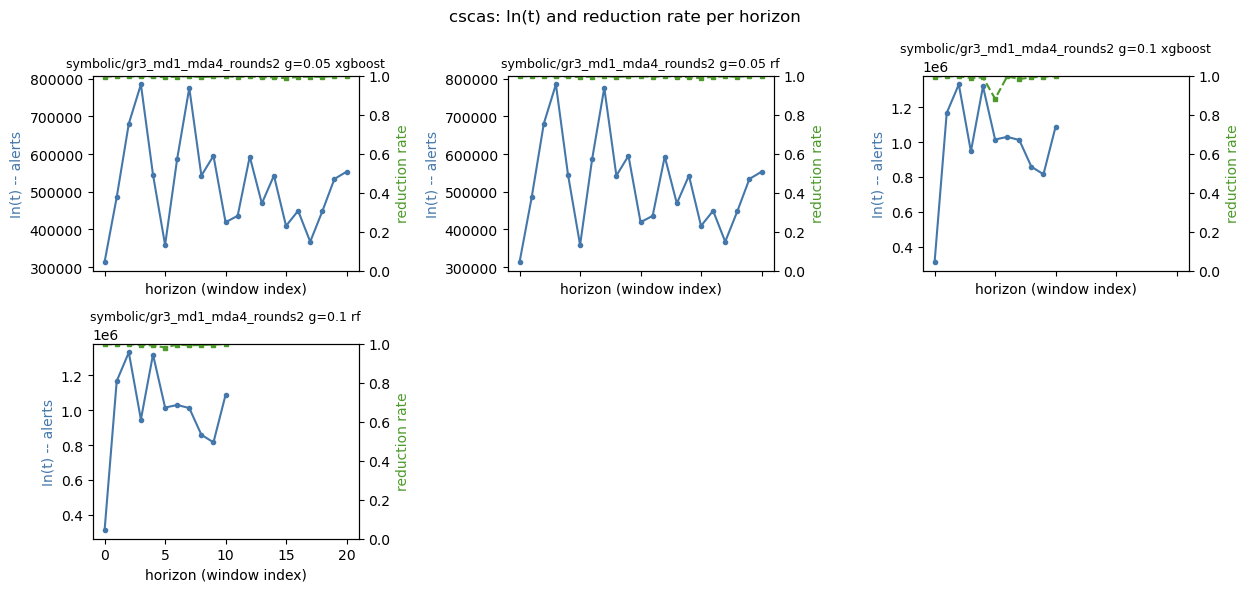

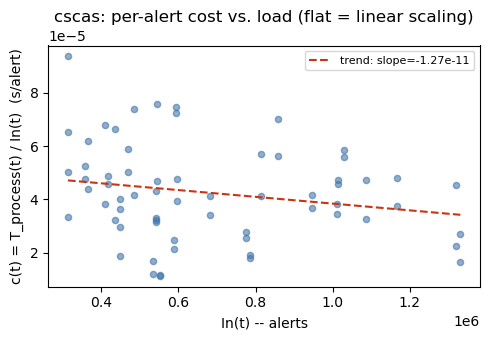

In [116]:
AACT_ALERTS_PER_MIN = 100  # literature sanity-check point, not a fitted target

if per_horizon_attached.empty:
    print("No monitor_attached run loaded.")
else:
    throughput_df = per_horizon_attached.dropna(subset=["fast_route_wall_s", "n_alerts_in"]).copy()
    throughput_df = throughput_df[throughput_df["fast_route_wall_s"] > 0]
    throughput_df["throughput_alerts_per_s"] = (
        throughput_df["n_alerts_in"] / throughput_df["fast_route_wall_s"]
    )
    throughput_df["throughput_alerts_per_min"] = throughput_df["throughput_alerts_per_s"] * 60
    throughput_df["reduction_rate"] = 1 - (
        throughput_df["n_alerts_escalated"] / throughput_df["n_alerts_in"]
    )
    throughput_df["cost_per_alert_s"] = (
        throughput_df["fast_route_wall_s"] / throughput_df["n_alerts_in"]
    )

    configs = ordered_configs(throughput_df)
    n = len(configs)
    ncols = 3
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.0 * nrows), squeeze=False, sharex=True)
    for i, cfg_row in configs.iterrows():
        ax = axes[i // ncols][i % ncols]
        mask = (throughput_df[CONFIG_COLS] == cfg_row).all(axis=1)
        sub = throughput_df[mask].sort_values("horizon_window_index")
        ax.plot(sub["horizon_window_index"], sub["n_alerts_in"], "-o", color=LINE_COLOR, ms=3, label="In(t)")
        ax.set_ylabel("In(t) -- alerts", color=LINE_COLOR)
        ax2 = ax.twinx()
        ax2.plot(sub["horizon_window_index"], sub["reduction_rate"], "--s", color="#4c9a2a", ms=3,
                  label="reduction rate")
        ax2.set_ylabel("reduction rate", color="#4c9a2a")
        ax2.set_ylim(0, 1)
        ax.set_title(config_label(cfg_row), fontsize=9)
        ax.set_xlabel("horizon (window index)")
    for j in range(n, nrows * ncols):
        axes[j // ncols][j % ncols].axis("off")
    fig.suptitle(f"{SCENARIO}: In(t) and reduction rate per horizon")
    fig.tight_layout()

    fig2, ax = plt.subplots(figsize=(5, 3.5))
    ax.scatter(throughput_df["n_alerts_in"], throughput_df["cost_per_alert_s"], s=20, alpha=0.6, color=LINE_COLOR)
    if len(throughput_df) >= 2:
        coeffs = np.polyfit(throughput_df["n_alerts_in"], throughput_df["cost_per_alert_s"], 1)
        xs = np.linspace(throughput_df["n_alerts_in"].min(), throughput_df["n_alerts_in"].max(), 50)
        ax.plot(xs, np.polyval(coeffs, xs), "--", color=SOURCE_COLOR,
                 label=f"trend: slope={coeffs[0]:.2e}")
        ax.legend(fontsize=8)
    ax.set_xlabel("In(t) -- alerts")
    ax.set_ylabel("c(t) = T_process(t) / In(t)  (s/alert)")
    ax.set_title(f"{SCENARIO}: per-alert cost vs. load (flat = linear scaling)")
    fig2.tight_layout()

    print("54-day-replay aggregate (all configs/horizons pooled):")
    print(f"  mean throughput: {throughput_df['throughput_alerts_per_min'].mean():.1f} alerts/min "
          f"(AACT reference: ~{AACT_ALERTS_PER_MIN} alerts/min)")
    print(f"  aggregate reduction rate: "
          f"{1 - throughput_df['n_alerts_escalated'].sum() / throughput_df['n_alerts_in'].sum():.1%}")
    heaviest = throughput_df.loc[throughput_df["n_alerts_in"].idxmax()]
    print(f"  heaviest horizon actually observed: n_alerts_in={int(heaviest['n_alerts_in'])} "
          f"({heaviest['feature_set']}/{heaviest['mining_setting']}, h={int(heaviest['horizon_window_index'])}) "
          f"-- no claim made beyond this point")

## 15. System Operationality 3 -- retraining / remining cost

Per executed event: `L_i = t_mining_s + t_retrain_s + t_deploy_s` (the
total remining latency -- how long the system runs on a stale schema/model
after staleness was detected before the fix goes live), `Churn_i` =
`churn_frac` (predicate-level, from `thesis.monitor.schema_diff`), `Cost_i`
= `mining_cpu_s + retrain_cpu_s`.

`Adaptation ratio = sum(L_i) / total fast-route serving time over the same
run` is the single summary number for "is continuous adaptation
affordable." External comparison points are kept in separate tiers, not
merged into one ranked table -- AACT is a different-scale deployed system
(sanity check only), Vaarandi 2024 is the fair same-scale numeric
comparison.

,feature_set,mining_setting,granularity,model,horizon_window_index,action,t_mining_s,t_retrain_s,t_deploy_s,L_i,churn_frac,Cost_i
0,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,2,REMINE_AND_RETRAIN,49.143258,10.867975,0.000003,60.011236,0.066667,81.125832
1,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,3,REMINE_AND_RETRAIN,40.710158,13.460424,0.330545,54.501127,0.062500,69.082341
2,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,6,REMINE_AND_RETRAIN,26.164104,12.450763,0.011920,38.626788,0.000000,49.146792
3,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,7,REMINE_AND_RETRAIN,33.340663,13.308730,0.000394,46.649787,0.281250,59.928669
4,symbolic,gr3_md1_mda4_rounds2,0.10,xgboost,10,REMINE_AND_RETRAIN,28.530636,12.440666,0.000380,40.971682,0.324324,54.279494
5,symbolic,gr3_md1_mda4_rounds2,0.10,rf,2,REMINE_AND_RETRAIN,44.094308,2.999388,0.000003,47.093698,0.066667,69.059967
6,symbolic,gr3_md1_mda4_rounds2,0.10,rf,3,REMINE_AND_RETRAIN,39.888055,2.522587,0.000454,42.411096,0.062500,53.059186
7,symbolic,gr3_md1_mda4_rounds2,0.10,rf,6,REMINE_AND_RETRAIN,45.710288,4.172613,0.005751,49.888651,0.000000,65.263139
8,symbolic,gr3_md1_mda4_rounds2,0.10,rf,7,REMINE_AND_RETRAIN,38.370438,5.073442,0.000542,43.444422,0.281250,49.716820
9,symbolic,gr3_md1_mda4_rounds2,0.10,rf,10,REMINE_AND_RETRAIN,16.278631,3.966221,0.000892,20.245745,0.324324,28.543434


Churn~L_i correlation: r=-0.25 (weak -- cost looks fixed-overhead-dominated)

L_i: mean=33.84s, median=34.80s, range=[2.23, 60.01]s, n=34
Total adaptation time = 1150.41s over total serving time = 1783.20s -> adaptation ratio = 64.5138%

Comparison (separate tiers, not merged):
  AACT (deployed, different scale, sanity check only): ~26 min = 1560s
  Vaarandi 2024 (same scale, fair comparison):
    cheapest (Uncertainty Sampling, RF): 240s-420s
    mid-range (Query-by-Committee): 720s-1080s
    most expensive (RBMAL): ?-10140s


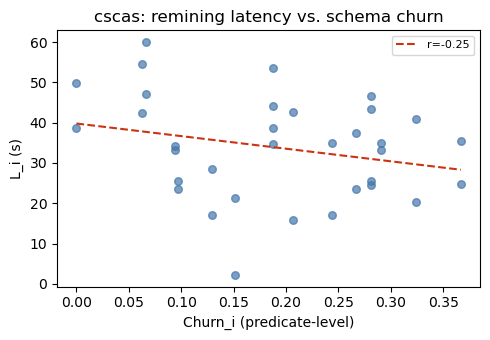

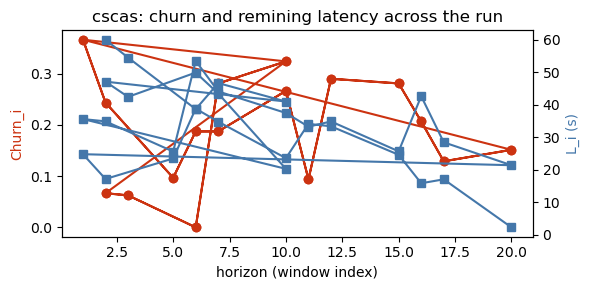

In [117]:
# Vaarandi 2024: same data scale, single Xeon server -- the fair numeric
# comparison. AACT: deployed, Kubernetes/Spark, different scale -- sanity
# check only. Minutes, converted to seconds for direct comparison with L_i.
VAARANDI_2024_MIN = {"cheapest (Uncertainty Sampling, RF)": (4, 7),
                       "mid-range (Query-by-Committee)": (12, 18),
                       "most expensive (RBMAL)": (None, 169)}
AACT_SPARK_MIN = 26

if events_attached.empty or not events_attached["executed"].any():
    print("No executed retrain/remine events in this run.")
else:
    cost_df = events_attached[events_attached["executed"]].copy()
    cost_df["L_i"] = cost_df[["t_mining_s", "t_retrain_s", "t_deploy_s"]].fillna(0).sum(axis=1)
    cost_df["Cost_i"] = cost_df[["mining_cpu_s", "retrain_cpu_s"]].fillna(0).sum(axis=1)

    display(cost_df[[*CONFIG_COLS, "horizon_window_index", "action", "t_mining_s",
                      "t_retrain_s", "t_deploy_s", "L_i", "churn_frac", "Cost_i"]])

    valid_churn = cost_df.dropna(subset=["churn_frac"])
    valid_churn = valid_churn[np.isfinite(valid_churn["churn_frac"])]
    if len(valid_churn) >= 2:
        fig, ax = plt.subplots(figsize=(5, 3.5))
        ax.scatter(valid_churn["churn_frac"], valid_churn["L_i"], s=30, alpha=0.7, color=LINE_COLOR)
        coeffs = np.polyfit(valid_churn["churn_frac"], valid_churn["L_i"], 1)
        r = np.corrcoef(valid_churn["churn_frac"], valid_churn["L_i"])[0, 1]
        xs = np.linspace(valid_churn["churn_frac"].min(), valid_churn["churn_frac"].max(), 50)
        ax.plot(xs, np.polyval(coeffs, xs), "--", color=SOURCE_COLOR, label=f"r={r:.2f}")
        ax.set_xlabel("Churn_i (predicate-level)")
        ax.set_ylabel("L_i (s)")
        ax.legend(fontsize=8)
        ax.set_title(f"{SCENARIO}: remining latency vs. schema churn")
        fig.tight_layout()
        print(f"Churn~L_i correlation: r={r:.2f} "
              f"({'tracks churn' if abs(r) > 0.3 else 'weak -- cost looks fixed-overhead-dominated'})")
    else:
        print("Not enough events with a defined churn_frac to regress (need >= 2).")

    fig2, ax2 = plt.subplots(figsize=(6, 3))
    ax2.plot(cost_df["horizon_window_index"], cost_df["churn_frac"], "-o", color=SOURCE_COLOR, label="Churn_i")
    ax2b = ax2.twinx()
    ax2b.plot(cost_df["horizon_window_index"], cost_df["L_i"], "-s", color=LINE_COLOR, label="L_i (s)")
    ax2.set_xlabel("horizon (window index)")
    ax2.set_ylabel("Churn_i", color=SOURCE_COLOR)
    ax2b.set_ylabel("L_i (s)", color=LINE_COLOR)
    ax2.set_title(f"{SCENARIO}: churn and remining latency across the run")
    fig2.tight_layout()

    total_fast_route_s = per_horizon_attached["fast_route_wall_s"].fillna(0).sum()
    total_L = cost_df["L_i"].sum()
    adaptation_ratio = total_L / total_fast_route_s if total_fast_route_s else float("nan")

    print(f"\nL_i: mean={cost_df['L_i'].mean():.2f}s, median={cost_df['L_i'].median():.2f}s, "
          f"range=[{cost_df['L_i'].min():.2f}, {cost_df['L_i'].max():.2f}]s, n={len(cost_df)}")
    print(f"Total adaptation time = {total_L:.2f}s over total serving time = {total_fast_route_s:.2f}s "
          f"-> adaptation ratio = {adaptation_ratio:.4%}")
    print(f"\nComparison (separate tiers, not merged):")
    print(f"  AACT (deployed, different scale, sanity check only): ~{AACT_SPARK_MIN} min = {AACT_SPARK_MIN*60:.0f}s")
    print(f"  Vaarandi 2024 (same scale, fair comparison):")
    for label, (lo, hi) in VAARANDI_2024_MIN.items():
        lo_s = f"{lo*60:.0f}s" if lo is not None else "?"
        print(f"    {label}: {lo_s}-{hi*60:.0f}s")

  saved -> src/thesis/notebooks/experiments/img/exp3/cscas_sysops_cost_slide_gran=0.1.png


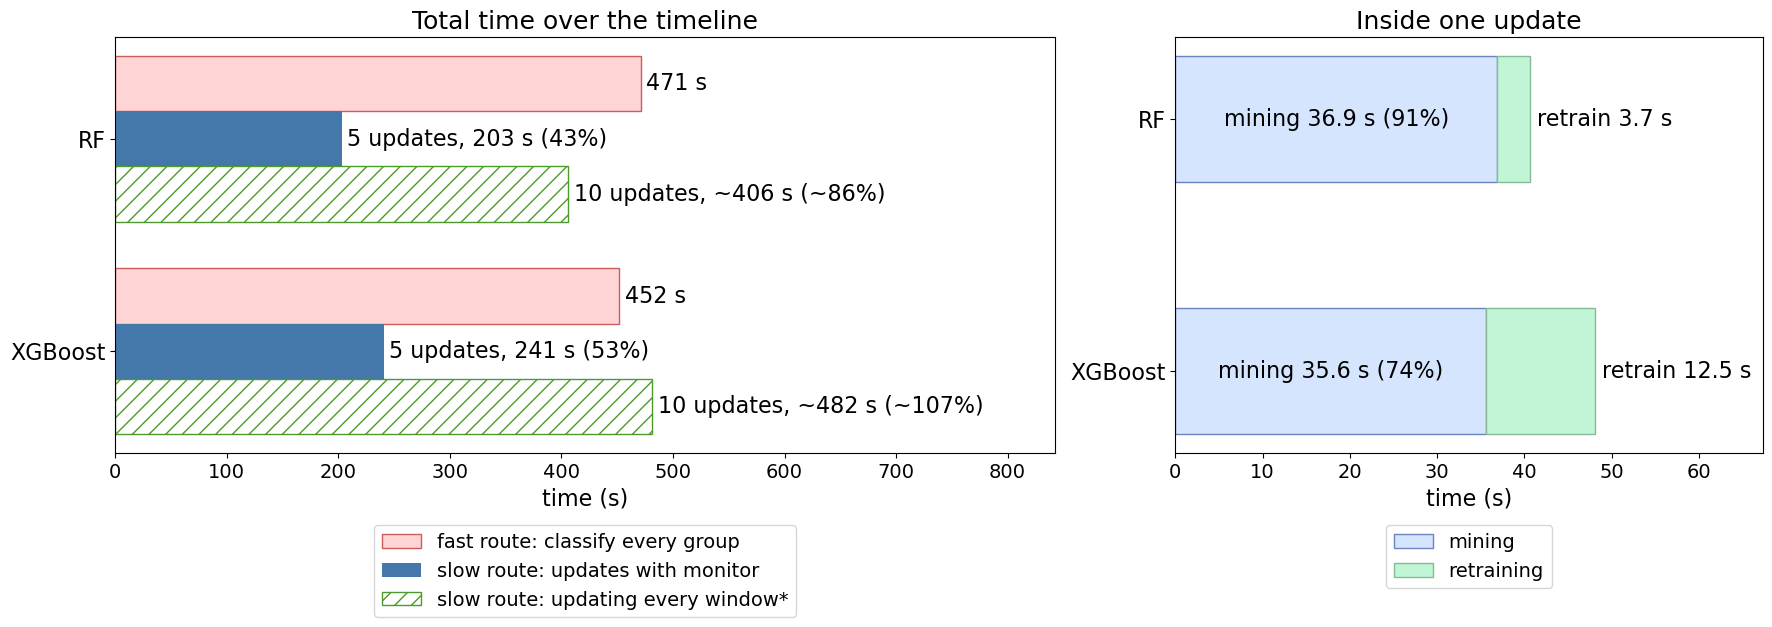

  saved -> src/thesis/notebooks/experiments/img/exp3/cscas_sysops_cost_slide_gran=0.05.png


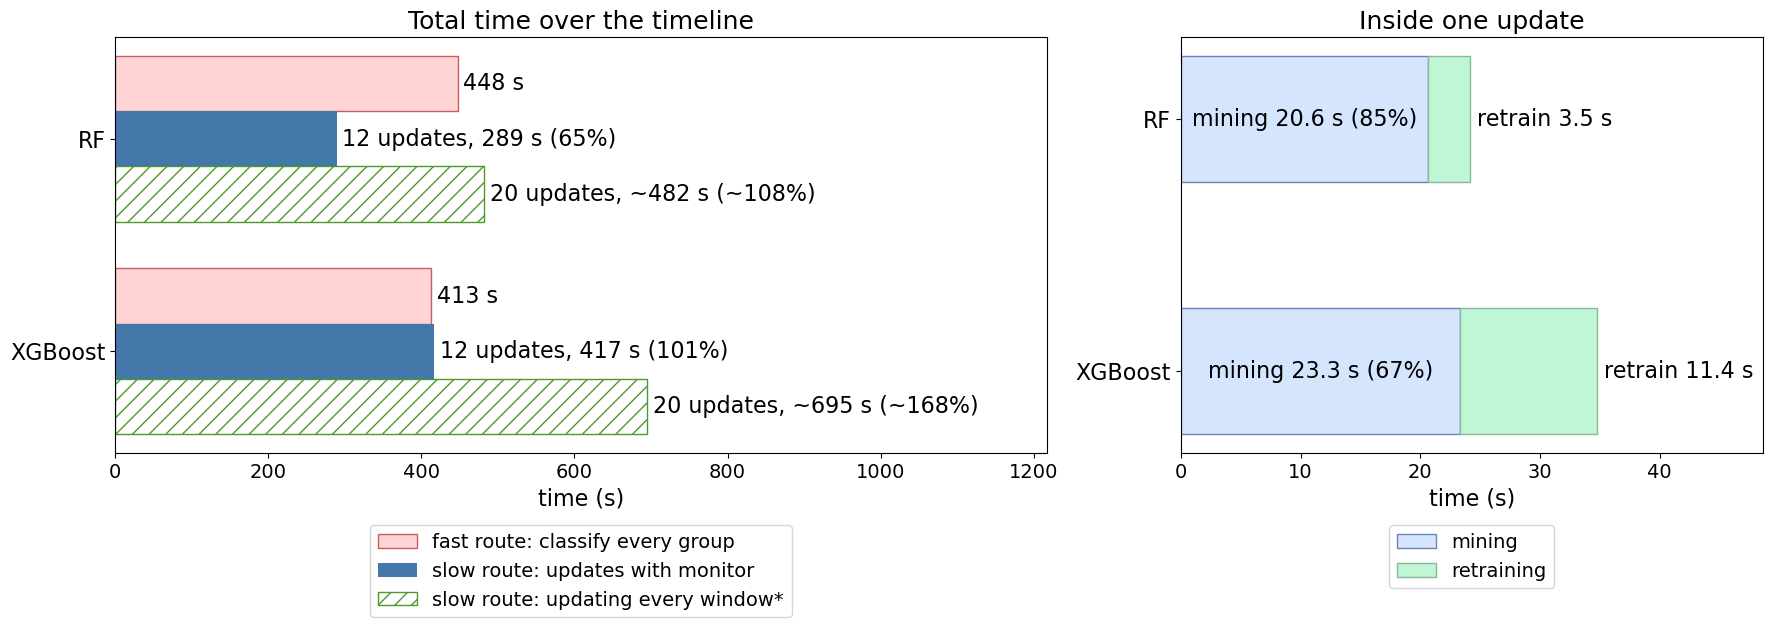

,model,n_windows,serve_s,n_monitor,monitor_s,n_always,always_s,mine_mean,retrain_mean,L_mean
0,rf,21,447.63,12,289.43,20,482.39,20.62,3.50,24.12
1,xgboost,21,412.61,12,417.13,20,695.21,23.29,11.42,34.76


In [118]:
# Slide: serving vs. updating cost over the whole walk (left) and what one
# update is made of (right), for one granularity. Everything is computed
# from per_horizon_attached / events_attached; the always-retrain bar is an
# estimate (n_updates x mean L_i) because the rolling_walk_forward run
# records no timings (its mining was a cache hit), relying on a single
# update costing the same whatever policy triggers it.
import numpy as np
from thesis.paths import ROOT

COST_MODELS = {"rf": "RF", "xgboost": "XGBoost"}
# Monitor / always-retrain use the same colours as the monitor-attached
# plots above (LINE_COLOR / green). Serving, mining and retraining take the
# architecture diagram's component colours (fill, outline): Classification
# (red), Knowledge discovery (blue), Adaptation (green).
COST_COLORS = {"monitor": LINE_COLOR, "always": "#4c9a2a",
               "serve": ("#FFD4D5", "#C75E5B"), "mine": ("#D5E5FE", "#6C84BB"),
               "retrain": ("#C0F6D6", "#87B997")}
COST_IMG = ROOT / "src/thesis/notebooks/experiments/img/exp3"


def sysops_cost_numbers(gran: float) -> pd.DataFrame:
    rows = []
    for model in COST_MODELS:
        ph = per_horizon_attached[per_horizon_attached["granularity"].eq(gran)
                                  & per_horizon_attached["model"].eq(model)]
        ev = events_attached[events_attached["granularity"].eq(gran)
                             & events_attached["model"].eq(model) & events_attached["executed"]]
        if ph.empty or ev.empty:
            continue
        L_i = ev[["t_mining_s", "t_retrain_s", "t_deploy_s"]].fillna(0).sum(axis=1)
        wf = per_step_walk_forward
        n_always = (len(wf[wf["feature_set"].eq(ph["feature_set"].iloc[0])
                           & wf["granularity"].eq(gran) & wf["model"].eq(model)])
                    if not wf.empty else len(ph) - 1)
        rows.append({
            "model": model, "n_windows": len(ph),
            "serve_s": ph["fast_route_wall_s"].sum(),
            "n_monitor": len(ev), "monitor_s": L_i.sum(),
            "n_always": n_always, "always_s": n_always * L_i.mean(),
            "mine_mean": ev["t_mining_s"].mean(), "retrain_mean": ev["t_retrain_s"].mean(),
            "L_mean": L_i.mean(),
        })
    return pd.DataFrame(rows)


def plot_sysops_cost_slide(gran: float = 0.1, label_fs: int = 16, tick_fs: int = 14,
                           save: bool = True) -> pd.DataFrame:
    """Slide footnote (not in the plot): * estimate = number of updates x
    mean time per update."""
    df = sysops_cost_numbers(gran)
    if df.empty:
        print(f"No monitor_attached data at gran={gran:g}.")
        return df
    labels = [COST_MODELS[m] for m in df["model"]]
    y = np.arange(len(df))
    fig, (axL, axR) = plt.subplots(1, 2, figsize=(18, 6.5),
                                   gridspec_kw={"width_ratios": [1.6, 1]})

    # -- left: total time over the walk ------------------------------------
    h = 0.26
    b1 = axL.barh(y - h, df["serve_s"], height=h, facecolor=COST_COLORS["serve"][0],
                  edgecolor=COST_COLORS["serve"][1], label="fast route: classify every group")
    b2 = axL.barh(y, df["monitor_s"], height=h, color=COST_COLORS["monitor"],
                  label="slow route: updates with monitor")
    b3 = axL.barh(y + h, df["always_s"], height=h, facecolor="white", edgecolor=COST_COLORS["always"],
                  hatch="//", label="slow route: updating every window*")
    axL.bar_label(b1, [f"{v:.0f} s" for v in df["serve_s"]], padding=4, fontsize=label_fs)
    axL.bar_label(b2, [f"{r.n_monitor} updates, {r.monitor_s:.0f} s ({r.monitor_s / r.serve_s:.0%})"
                       for r in df.itertuples()], padding=4, fontsize=label_fs)
    axL.bar_label(b3, [f"{r.n_always} updates, ~{r.always_s:.0f} s (~{r.always_s / r.serve_s:.0%})"
                       for r in df.itertuples()], padding=4, fontsize=label_fs)
    axL.set_yticks(y, labels)
    axL.invert_yaxis()
    axL.set_xlim(0, df[["serve_s", "monitor_s", "always_s"]].to_numpy().max() * 1.75)
    axL.set_title("Total time over the timeline", fontsize=label_fs + 2)
    axL.legend(fontsize=tick_fs, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=1)

    # -- right: inside one update -----------------------------------------
    # mining labelled inside its segment, retrain just right of the bar --
    # the retrain segment is too narrow (RF: 3.7 s) to hold a label inside
    r1 = axR.barh(y, df["mine_mean"], height=0.5, facecolor=COST_COLORS["mine"][0],
                  edgecolor=COST_COLORS["mine"][1], label="mining")
    r2 = axR.barh(y, df["retrain_mean"], left=df["mine_mean"], height=0.5,
                  facecolor=COST_COLORS["retrain"][0], edgecolor=COST_COLORS["retrain"][1],
                  label="retraining")
    share = df["mine_mean"] / (df["mine_mean"] + df["retrain_mean"])
    axR.bar_label(r1, [f"mining {m:.1f} s ({s:.0%})" for m, s in zip(df["mine_mean"], share)],
                  label_type="center", fontsize=label_fs)
    axR.bar_label(r2, [f"retrain {v:.1f} s" for v in df["retrain_mean"]], padding=5,
                  fontsize=label_fs)
    axR.set_yticks(y, labels)
    axR.invert_yaxis()
    axR.set_xlim(0, (df["mine_mean"] + df["retrain_mean"]).max() * 1.4)
    axR.set_title("Inside one update", fontsize=label_fs + 2)
    axR.legend(fontsize=tick_fs, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=1)

    for ax in (axL, axR):
        ax.set_xlabel("time (s)", fontsize=label_fs)
        ax.tick_params(labelsize=tick_fs)
        ax.tick_params(axis="y", labelsize=label_fs)
    fig.tight_layout()
    if save:
        COST_IMG.mkdir(parents=True, exist_ok=True)
        path = COST_IMG / f"{SCENARIO}_sysops_cost_slide_gran={gran:g}.png"
        fig.savefig(path, dpi=300, bbox_inches="tight")
        print(f"  saved -> {path.relative_to(ROOT)}")
    plt.show()
    return df.round(2)


plot_sysops_cost_slide(0.1)
plot_sysops_cost_slide(0.05)

## 16. System Operationality 4 -- workload reduction

**Ungroupability is out of scope**: CSCAS is pregrouped
(`CSCAS_PREGROUPED_METHOD`), so `G_ungroupable = 0` always, `Share_ungroupable`
is not applicable, and the funnel collapses to two buckets: `G_suppressed`
(below threshold) and `G_escalated` (at/above threshold) -- exactly
`n_groups_suppressed`/`n_groups_escalated` (and their `n_alerts_*`
counterparts) already logged per horizon in `per_horizon_attached`.
`R_manual = R_escalated` here (no separate ungroupable contribution).

Validity checks use the labeled subset already scored each horizon:
FPR/FNR of `G_suppressed` = the miss rate among predicted-negative groups
(`fn / (fn + tn)`, from the confusion-matrix columns already in
`per_horizon_attached`); attack rate in escalated = precision
(`tp / (tp + fp)`), compared against the horizon's overall `attack_rate_h`.

Headline aggregates (whole run, all configs/horizons pooled):
  N (raw alerts in) = 43576852, G (alert groups) = 5190608
  R_escalated = 1.4%, R_suppressed = 98.6%, R_manual = 1.4%
  ARR (raw-alert granularity) = 99.1%
  Share_ungroupable: N/A (CSCAS is pregrouped)

Analyst-hours-saved sensitivity (t_alert assumed = 60s/raw alert):
  t_group = 1x t_alert (60s/group): 639,770.7 analyst-hours saved
  t_group = 2x t_alert (120s/group): 553,260.6 analyst-hours saved
  t_group = 5x t_alert (300s/group): 293,730.2 analyst-hours saved

Cost per alert avoided (CPU-seconds) = (1954.04 fast-route + 1433.64 slow-route) / 43186774 suppressed alerts = 0.000078 CPU-s/alert-avoided

Validity checks (labeled subset only):
  FNR of G_suppressed (fn / (fn+tn)) = 0.19% -- fraction of predicted-negative groups that were actually attacks
  Attack rate within G_escalated (precision) = 92.93% vs. baseline attack_rate = 1.51%


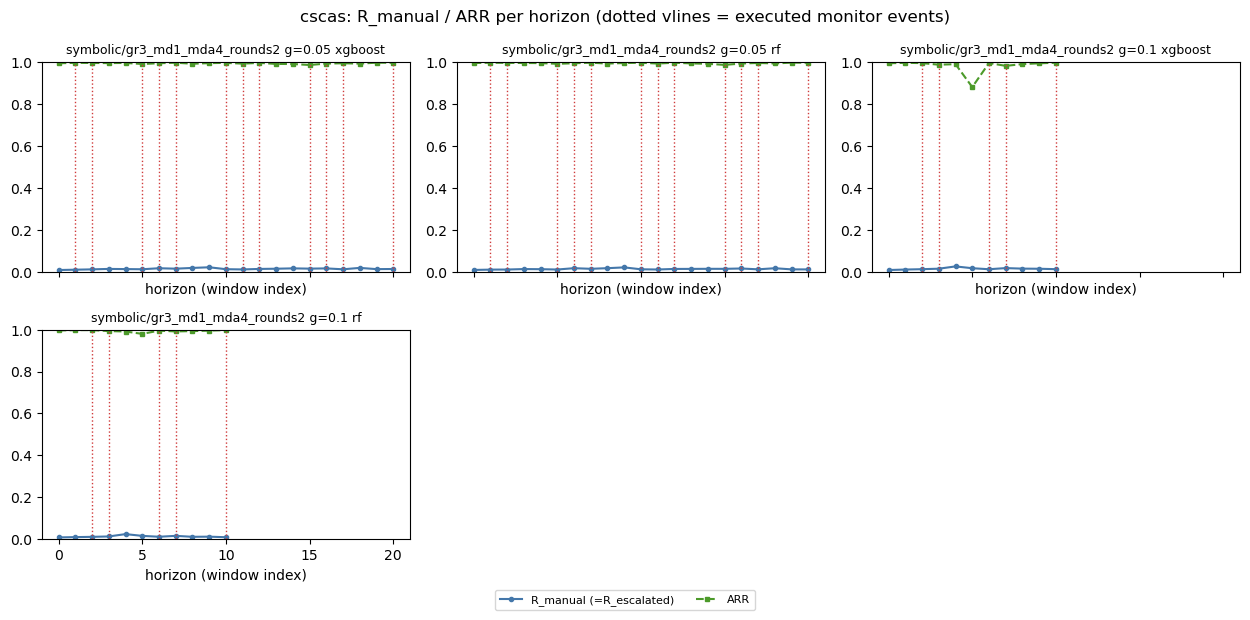

In [119]:
T_ALERT_ASSUMED_S = 60  # assumed per-raw-alert review time (counterfactual: no system)
T_GROUP_MULTIPLIERS = (1, 2, 5)  # t_group = k * t_alert, sensitivity sweep

if per_horizon_attached.empty:
    print("No monitor_attached run loaded.")
else:
    funnel_df = per_horizon_attached.dropna(subset=["n_alerts_in"]).copy()

    N = funnel_df["n_alerts_in"].sum()
    G = funnel_df["n_alert_groups"].sum()
    G_escalated = funnel_df["n_groups_escalated"].sum()
    G_suppressed = funnel_df["n_groups_suppressed"].sum()
    N_escalated = funnel_df["n_alerts_escalated"].sum()
    N_suppressed = funnel_df["n_alerts_suppressed"].sum()

    R_escalated = G_escalated / G if G else float("nan")
    R_suppressed = G_suppressed / G if G else float("nan")
    R_manual = R_escalated  # no ungroupable contribution here
    ARR = 1 - (N_escalated / N) if N else float("nan")  # raw-alert granularity, ungroupable=0

    print("Headline aggregates (whole run, all configs/horizons pooled):")
    print(f"  N (raw alerts in) = {int(N)}, G (alert groups) = {int(G)}")
    print(f"  R_escalated = {R_escalated:.1%}, R_suppressed = {R_suppressed:.1%}, R_manual = {R_manual:.1%}")
    print(f"  ARR (raw-alert granularity) = {ARR:.1%}")
    print(f"  Share_ungroupable: N/A (CSCAS is pregrouped)")

    print("\nAnalyst-hours-saved sensitivity (t_alert assumed = "
          f"{T_ALERT_ASSUMED_S}s/raw alert):")
    for k in T_GROUP_MULTIPLIERS:
        t_group = k * T_ALERT_ASSUMED_S
        hours_saved = (N * T_ALERT_ASSUMED_S - G * t_group) / 3600
        print(f"  t_group = {k}x t_alert ({t_group}s/group): {hours_saved:,.1f} analyst-hours saved")

    total_fast_route_s = per_horizon_attached["fast_route_wall_s"].fillna(0).sum()
    total_slow_route_cpu_s = (
        events_attached.loc[events_attached["executed"], ["mining_cpu_s", "retrain_cpu_s"]]
        .fillna(0).sum().sum()
        if not events_attached.empty else 0
    )
    total_fast_route_cpu_s = per_horizon_attached["fast_route_cpu_s"].fillna(0).sum()
    cost_per_alert_avoided = (
        (total_fast_route_cpu_s + total_slow_route_cpu_s) / N_suppressed if N_suppressed else float("nan")
    )
    print(f"\nCost per alert avoided (CPU-seconds) = "
          f"({total_fast_route_cpu_s:.2f} fast-route + {total_slow_route_cpu_s:.2f} slow-route) / "
          f"{int(N_suppressed)} suppressed alerts = {cost_per_alert_avoided:.6f} CPU-s/alert-avoided")

    # Time series, day-axis overlay with monitor trigger events.
    configs = ordered_configs(funnel_df)
    n = len(configs)
    ncols = 3
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.0 * nrows), squeeze=False, sharex=True)
    for i, cfg_row in configs.iterrows():
        ax = axes[i // ncols][i % ncols]
        mask = (funnel_df[CONFIG_COLS] == cfg_row).all(axis=1)
        sub = funnel_df[mask].sort_values("horizon_window_index")
        r_esc_h = sub["n_groups_escalated"] / sub["n_alert_groups"]
        arr_h = 1 - sub["n_alerts_escalated"] / sub["n_alerts_in"]
        ax.plot(sub["horizon_window_index"], r_esc_h, "-o", color=LINE_COLOR, ms=3, label="R_manual (=R_escalated)")
        ax.plot(sub["horizon_window_index"], arr_h, "--s", color="#4c9a2a", ms=3, label="ARR")
        ev_mask = (events_attached[CONFIG_COLS] == cfg_row).all(axis=1) if not events_attached.empty else None
        if ev_mask is not None:
            executed = events_attached[ev_mask & events_attached["executed"]]
            for action, group in executed.groupby("action"):
                ax.axvline(0, alpha=0)  # keep axes stable even with no executed events
                for h in group["horizon_window_index"]:
                    ax.axvline(h, color=ACTION_COLORS.get(action, "#898781"), linestyle=":", linewidth=1)
        ax.set_ylim(0, 1)
        ax.set_title(config_label(cfg_row), fontsize=9)
        ax.set_xlabel("horizon (window index)")
    for j in range(n, nrows * ncols):
        axes[j // ncols][j % ncols].axis("off")
    handles, labels = axes[0][0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.03), fontsize=8)
    fig.suptitle(f"{SCENARIO}: R_manual / ARR per horizon (dotted vlines = executed monitor events)")
    fig.tight_layout()

    # Validity checks.
    labeled = per_horizon_attached.dropna(subset=["tp", "fp", "tn", "fn"])
    if not labeled.empty:
        fnr_suppressed = labeled["fn"].sum() / (labeled["fn"].sum() + labeled["tn"].sum())
        precision_escalated = labeled["tp"].sum() / (labeled["tp"].sum() + labeled["fp"].sum())
        baseline_attack_rate = labeled["n_attack"].sum() / labeled["n_alert_groups"].sum()
        print(f"\nValidity checks (labeled subset only):")
        print(f"  FNR of G_suppressed (fn / (fn+tn)) = {fnr_suppressed:.2%} "
              "-- fraction of predicted-negative groups that were actually attacks")
        print(f"  Attack rate within G_escalated (precision) = {precision_escalated:.2%} "
              f"vs. baseline attack_rate = {baseline_attack_rate:.2%}")
    else:
        print("\nNo labeled horizons available for the validity checks.")

## 17. System Operationality -- per-config tables (LaTeX)

The four System Operationality sections above report pooled aggregates
(all configs/horizons together). These four tables give the same
quantities broken out per config (granularity x model), one table per
subsection, for the thesis write-up.

In [120]:
def _fmt(v, nd=2) -> str:
    return "--" if pd.isna(v) else f"{v:.{nd}f}"


def _gran_col(df, i) -> str:
    return f"{df.loc[i, 'gran']:g}" if i == 0 or df.loc[i, 'gran'] != df.loc[i - 1, 'gran'] else ""


def build_sysops_tables():
    configs = per_horizon_attached[CONFIG_COLS].drop_duplicates().sort_values(["granularity", "model"]).reset_index(drop=True)
    rows1, rows2, rows3, rows4 = [], [], [], []

    for _, cfg in configs.iterrows():
        m_ph = (per_horizon_attached[CONFIG_COLS] == cfg).all(axis=1)
        sub_ph = per_horizon_attached[m_ph].copy()
        m_ev = (events_attached[CONFIG_COLS] == cfg).all(axis=1)
        executed = events_attached[m_ev & events_attached["executed"]]
        m_lat = (latency_attached[CONFIG_COLS] == cfg).all(axis=1)
        sub_lat = latency_attached[m_lat]
        gran, model = cfg["granularity"], cfg["model"]

        # Table 1: fast route vs. slow route cost.
        fr = sub_ph["fast_route_wall_s"].dropna()
        lat = sub_lat["latency_s"]
        L_i = executed[["t_mining_s", "t_retrain_s", "t_deploy_s"]].fillna(0).sum(axis=1)
        rows1.append({
            "gran": gran, "model": model,
            "fr_mean": fr.mean(), "fr_p95": fr.quantile(0.95), "fr_p99": fr.quantile(0.99),
            "lat_mean": lat.mean(), "lat_p95": lat.quantile(0.95), "lat_p99": lat.quantile(0.99),
            "Li_mean": L_i.mean(), "n_events": len(executed),
        })

        # Table 2: throughput and alert reduction.
        tdf = sub_ph.dropna(subset=["fast_route_wall_s", "n_alerts_in"])
        tdf = tdf[tdf["fast_route_wall_s"] > 0]
        throughput = (tdf["n_alerts_in"] / tdf["fast_route_wall_s"]) * 60
        reduction = 1 - tdf["n_alerts_escalated"].sum() / tdf["n_alerts_in"].sum()
        rows2.append({
            "gran": gran, "model": model,
            "mean_in": tdf["n_alerts_in"].mean(), "max_in": tdf["n_alerts_in"].max(),
            "mean_throughput": throughput.mean(), "reduction_rate": reduction,
        })

        # Table 3: retraining/remining cost.
        Cost_i = executed[["mining_cpu_s", "retrain_cpu_s"]].fillna(0).sum(axis=1)
        total_fr = sub_ph["fast_route_wall_s"].fillna(0).sum()
        adaptation_ratio = L_i.sum() / total_fr if total_fr else float("nan")
        churn = executed["churn_frac"].dropna()
        rows3.append({
            "gran": gran, "model": model, "n_events": len(executed),
            "Li_mean": L_i.mean(), "Li_median": L_i.median(),
            "churn_mean": churn.mean(), "Cost_i_mean": Cost_i.mean(),
            "adaptation_ratio": adaptation_ratio,
        })

        # Table 4: workload reduction.
        N, G = sub_ph["n_alerts_in"].sum(), sub_ph["n_alert_groups"].sum()
        G_esc, N_esc = sub_ph["n_groups_escalated"].sum(), sub_ph["n_alerts_escalated"].sum()
        N_sup = sub_ph["n_alerts_suppressed"].sum()
        R_esc = G_esc / G if G else float("nan")
        ARR = 1 - N_esc / N if N else float("nan")
        labeled = sub_ph.dropna(subset=["tp", "fp", "tn", "fn"])
        fnr = labeled["fn"].sum() / (labeled["fn"].sum() + labeled["tn"].sum()) if not labeled.empty else float("nan")
        prec = labeled["tp"].sum() / (labeled["tp"].sum() + labeled["fp"].sum()) if not labeled.empty else float("nan")
        total_fr_cpu = sub_ph["fast_route_cpu_s"].fillna(0).sum()
        total_slow_cpu = executed[["mining_cpu_s", "retrain_cpu_s"]].fillna(0).sum().sum()
        cost_per_avoided = (total_fr_cpu + total_slow_cpu) / N_sup if N_sup else float("nan")
        rows4.append({
            "gran": gran, "model": model, "N": N, "G": G, "R_esc": R_esc, "ARR": ARR,
            "fnr": fnr, "prec": prec, "cost_per_avoided": cost_per_avoided,
        })

    return pd.DataFrame(rows1), pd.DataFrame(rows2), pd.DataFrame(rows3), pd.DataFrame(rows4)


sysops_t1, sysops_t2, sysops_t3, sysops_t4 = build_sysops_tables()
sysops_t1

,gran,model,fr_mean,fr_p95,fr_p99,lat_mean,lat_p95,lat_p99,Li_mean,n_events
0,0.05,rf,21.315687,41.330280,43.678485,0.667232,2.111245,2.750207,24.119532,12
1,0.05,xgboost,19.647992,27.729515,39.979459,0.094057,0.194316,0.826814,34.760748,12
2,0.10,rf,42.841091,60.075900,60.281358,0.840344,2.194876,3.176897,40.616723,5
3,0.10,xgboost,41.064305,58.891691,59.978549,0.090548,0.304789,0.623654,48.152124,5


### Table: fast route vs. slow route cost (LaTeX)

In [121]:
lines = [
    r"\begin{table}[h]", r"\centering", r"\footnotesize",
    r"\begin{tabular}{llrrrrrrrr}", r"\toprule",
    r"\textbf{Gran} & \textbf{Model} & \multicolumn{3}{c}{Fast route (s, batched)} & "
    r"\multicolumn{3}{c}{Single-alert latency (s)} & $L_i$ mean & \# events \\",
    r" & & mean & p95 & p99 & mean & p95 & p99 & (s) & \\",
    r"\midrule",
]
for i, row in sysops_t1.iterrows():
    lines.append(
        f"{_gran_col(sysops_t1, i)} & {row['model']} & {_fmt(row['fr_mean'])} & {_fmt(row['fr_p95'])} & "
        f"{_fmt(row['fr_p99'])} & {_fmt(row['lat_mean'], 3)} & {_fmt(row['lat_p95'], 3)} & "
        f"{_fmt(row['lat_p99'], 3)} & {_fmt(row['Li_mean'])} & {int(row['n_events'])} \\\\"
    )
lines += [r"\bottomrule", r"\end{tabular}"]
lines.append(
    r"\caption{Fast route vs.\ slow route cost, per config. Fast route = batched "
    r"encode+predict wall time, one call per horizon over every incoming group; "
    r"single-alert latency = individually-timed single-group calls "
    r"(\texttt{latency\_sample.csv}); $L_i$ mean = mean per-event remining latency "
    r"($t_\text{mining}+t_\text{retrain}+t_\text{deploy}$) over executed events only.}"
)
lines.append(r"\label{tab:sysops-fast-slow-route}")
lines.append(r"\end{table}")
print("\n".join(lines))

\begin{table}[h]
\centering
\footnotesize
\begin{tabular}{llrrrrrrrr}
\toprule
\textbf{Gran} & \textbf{Model} & \multicolumn{3}{c}{Fast route (s, batched)} & \multicolumn{3}{c}{Single-alert latency (s)} & $L_i$ mean & \# events \\
 & & mean & p95 & p99 & mean & p95 & p99 & (s) & \\
\midrule
0.05 & rf & 21.32 & 41.33 & 43.68 & 0.667 & 2.111 & 2.750 & 24.12 & 12 \\
 & xgboost & 19.65 & 27.73 & 39.98 & 0.094 & 0.194 & 0.827 & 34.76 & 12 \\
0.1 & rf & 42.84 & 60.08 & 60.28 & 0.840 & 2.195 & 3.177 & 40.62 & 5 \\
 & xgboost & 41.06 & 58.89 & 59.98 & 0.091 & 0.305 & 0.624 & 48.15 & 5 \\
\bottomrule
\end{tabular}
\caption{Fast route vs.\ slow route cost, per config. Fast route = batched encode+predict wall time, one call per horizon over every incoming group; single-alert latency = individually-timed single-group calls (\texttt{latency\_sample.csv}); $L_i$ mean = mean per-event remining latency ($t_\text{mining}+t_\text{retrain}+t_\text{deploy}$) over executed events only.}
\label{tab:sysops-f

### Table: throughput and alert reduction (LaTeX)

In [122]:
lines = [
    r"\begin{table}[h]", r"\centering", r"\footnotesize",
    r"\begin{tabular}{llrrrr}", r"\toprule",
    r"\textbf{Gran} & \textbf{Model} & Mean In($t$) & Max In($t$) & Mean throughput (alerts/min) & Reduction rate \\",
    r"\midrule",
]
for i, row in sysops_t2.iterrows():
    lines.append(
        (f"{_gran_col(sysops_t2, i)} & {row['model']} & {row['mean_in']:,.0f} & {row['max_in']:,.0f} & "
         f"{row['mean_throughput']:,.0f} & {row['reduction_rate']:.1%} \\\\").replace("%", "\\%")
    )
lines += [r"\bottomrule", r"\end{tabular}"]
lines.append(
    r"\caption{Throughput and alert reduction, per config. In($t$) = \texttt{n\_alerts\_in} "
    r"(incoming raw alerts) at horizon $t$; throughput = In($t$)/fast-route wall time, alerts/min; "
    r"reduction rate = $1 - $Out($t$)/In($t$), pooled across all horizons for that config "
    r"(Out($t$) = \texttt{n\_alerts\_escalated}).}"
)
lines.append(r"\label{tab:sysops-throughput}")
lines.append(r"\end{table}")
print("\n".join(lines))

\begin{table}[h]
\centering
\footnotesize
\begin{tabular}{llrrrr}
\toprule
\textbf{Gran} & \textbf{Model} & Mean In($t$) & Max In($t$) & Mean throughput (alerts/min) & Reduction rate \\
\midrule
0.05 & rf & 518,772 & 785,279 & 1,902,742 & 99.5\% \\
 & xgboost & 518,772 & 785,279 & 1,867,925 & 99.4\% \\
0.1 & rf & 990,383 & 1,330,681 & 1,501,647 & 99.3\% \\
 & xgboost & 990,383 & 1,330,681 & 1,564,998 & 98.2\% \\
\bottomrule
\end{tabular}
\caption{Throughput and alert reduction, per config. In($t$) = \texttt{n\_alerts\_in} (incoming raw alerts) at horizon $t$; throughput = In($t$)/fast-route wall time, alerts/min; reduction rate = $1 - $Out($t$)/In($t$), pooled across all horizons for that config (Out($t$) = \texttt{n\_alerts\_escalated}).}
\label{tab:sysops-throughput}
\end{table}


### Table: retraining/remining cost (LaTeX)

In [123]:
lines = [
    r"\begin{table}[h]", r"\centering", r"\footnotesize",
    r"\begin{tabular}{llrrrrrr}", r"\toprule",
    r"\textbf{Gran} & \textbf{Model} & \# events & $L_i$ mean (s) & $L_i$ median (s) & "
    r"Churn$_i$ mean & Cost$_i$ mean (CPU-s) & Adaptation ratio \\",
    r"\midrule",
]
for i, row in sysops_t3.iterrows():
    lines.append(
        (f"{_gran_col(sysops_t3, i)} & {row['model']} & {int(row['n_events'])} & {_fmt(row['Li_mean'])} & "
         f"{_fmt(row['Li_median'])} & {_fmt(row['churn_mean'], 3)} & {_fmt(row['Cost_i_mean'])} & "
         f"{row['adaptation_ratio']:.1%} \\\\").replace("%", "\\%")
    )
lines += [r"\bottomrule", r"\end{tabular}"]
lines.append(
    r"\caption{Retraining/remining cost, per config. $L_i = t_\text{mining}+t_\text{retrain}+t_\text{deploy}$ "
    r"per executed event; Cost$_i$ = mining\_cpu\_s + retrain\_cpu\_s; adaptation ratio = "
    r"$\sum L_i$ / total fast-route serving time for that config (values above 100\% mean the "
    r"config spent more time adapting than serving over this walk).}"
)
lines.append(r"\label{tab:sysops-retrain-cost}")
lines.append(r"\end{table}")
print("\n".join(lines))

\begin{table}[h]
\centering
\footnotesize
\begin{tabular}{llrrrrrr}
\toprule
\textbf{Gran} & \textbf{Model} & \# events & $L_i$ mean (s) & $L_i$ median (s) & Churn$_i$ mean & Cost$_i$ mean (CPU-s) & Adaptation ratio \\
\midrule
0.05 & rf & 12 & 24.12 & 24.05 & 0.208 & 29.47 & 64.7\% \\
 & xgboost & 12 & 34.76 & 34.85 & 0.208 & 41.73 & 101.1\% \\
0.1 & rf & 5 & 40.62 & 43.44 & 0.147 & 53.13 & 43.1\% \\
 & xgboost & 5 & 48.15 & 46.65 & 0.147 & 62.71 & 53.3\% \\
\bottomrule
\end{tabular}
\caption{Retraining/remining cost, per config. $L_i = t_\text{mining}+t_\text{retrain}+t_\text{deploy}$ per executed event; Cost$_i$ = mining\_cpu\_s + retrain\_cpu\_s; adaptation ratio = $\sum L_i$ / total fast-route serving time for that config (values above 100\% mean the config spent more time adapting than serving over this walk).}
\label{tab:sysops-retrain-cost}
\end{table}


### Table: workload reduction (LaTeX)

In [124]:
lines = [
    r"\begin{table}[h]", r"\centering", r"\footnotesize",
    r"\begin{tabular}{llrrrrrr}", r"\toprule",
    r"\textbf{Gran} & \textbf{Model} & $N$ & $G$ & $R_\text{escalated}$ & ARR & FNR$_\text{suppr.}$ & Precision$_\text{esc.}$ \\",
    r"\midrule",
]
for i, row in sysops_t4.iterrows():
    lines.append(
        (f"{_gran_col(sysops_t4, i)} & {row['model']} & {row['N']:,.0f} & {row['G']:,.0f} & "
         f"{row['R_esc']:.2%} & {row['ARR']:.2%} & {row['fnr']:.2%} & {row['prec']:.2%} \\\\").replace("%", "\\%")
    )
lines += [r"\bottomrule", r"\end{tabular}"]
lines.append(
    r"\caption{Workload reduction, per config. $N$ = raw alerts in, $G$ = alert groups; "
    r"$R_\text{escalated} = G_\text{escalated}/G$ ($=R_\text{manual}$, no ungroupable bucket -- "
    r"CSCAS is pregrouped); ARR = $1 - N_\text{escalated}/N$ (raw-alert granularity); "
    r"FNR$_\text{suppr.}$ = fn/(fn+tn) among suppressed groups; Precision$_\text{esc.}$ = "
    r"tp/(tp+fp) among escalated groups (validity checks, labeled subset only).}"
)
lines.append(r"\label{tab:sysops-workload}")
lines.append(r"\end{table}")
print("\n".join(lines))

\begin{table}[h]
\centering
\footnotesize
\begin{tabular}{llrrrrrr}
\toprule
\textbf{Gran} & \textbf{Model} & $N$ & $G$ & $R_\text{escalated}$ & ARR & FNR$_\text{suppr.}$ & Precision$_\text{esc.}$ \\
\midrule
0.05 & rf & 10,894,213 & 1,297,652 & 1.36\% & 99.49\% & 0.24\% & 94.06\% \\
 & xgboost & 10,894,213 & 1,297,652 & 1.43\% & 99.43\% & 0.20\% & 91.70\% \\
0.1 & rf & 10,894,213 & 1,297,652 & 1.37\% & 99.31\% & 0.22\% & 94.53\% \\
 & xgboost & 10,894,213 & 1,297,652 & 1.51\% & 98.19\% & 0.13\% & 91.63\% \\
\bottomrule
\end{tabular}
\caption{Workload reduction, per config. $N$ = raw alerts in, $G$ = alert groups; $R_\text{escalated} = G_\text{escalated}/G$ ($=R_\text{manual}$, no ungroupable bucket -- CSCAS is pregrouped); ARR = $1 - N_\text{escalated}/N$ (raw-alert granularity); FNR$_\text{suppr.}$ = fn/(fn+tn) among suppressed groups; Precision$_\text{esc.}$ = tp/(tp+fp) among escalated groups (validity checks, labeled subset only).}
\label{tab:sysops-workload}
\end{table}
